# Proyecto integrador de Ciencia de Datos e Inteligencia Artificial

**Fase 1:** Planteamiento del problema, descripción del dataset y análisis exploratorio de datos (EDA)

**Asignatura:** Ciencia de Datos  
**Programa:** Maestría en Inteligencia Artificial  
**Estudiante:** Jennifer Juliana Bayona Rojas

Enlace del notebook https://colab.research.google.com/drive/1akugrY6ouwUKdYYqveQEB9U_C9MOASSF?usp=sharing

---

## 1. Formulación del problema

### 1.1 Contextualización del problema

El comercio electrónico genera información sobre clientes, productos, pedidos, pagos y entregas. El análisis de estos datos permite estudiar el comportamiento de compra, reconocer diferencias en el valor de los pedidos e identificar características asociadas con las devoluciones.

En este proyecto utilizo el conjunto de datos **E-Commerce Sales Analytics Dataset**, publicado en Kaggle. El análisis se centra en la tabla de ventas, con una fila por pedido, para estimar la venta neta en USD, estudiar el riesgo de devolución y agrupar pedidos en USD según sus características.

El problema consiste en establecer cómo se relacionan estas características y qué información pueden aportar para orientar decisiones comerciales. Para ello, primero es necesario revisar la calidad de los datos, comprender sus variables y explorar sus distribuciones y relaciones. También se deben considerar las diferencias entre monedas y entre las unidades de análisis, ya que un pedido puede contener varias líneas de productos.

### 1.2 Impacto potencial de la solución

Los resultados podrían apoyar la planificación comercial mediante estimaciones del valor de los pedidos, aportar información para revisar procesos asociados con las devoluciones y orientar acciones comerciales según el perfil del pedido.

Estas aplicaciones se plantean como posibilidades del proyecto. Su utilidad dependerá de la calidad de los datos y del desempeño de los modelos en las fases posteriores. Las asociaciones encontradas durante el análisis exploratorio no se interpretarán como relaciones de causa y efecto.

### 1.3 Pregunta de investigación principal

¿Cómo pueden utilizarse las características de los pedidos y de los clientes para estimar la venta neta en USD, identificar el riesgo de devolución y distinguir perfiles de pedidos en USD?

### 1.4 Preguntas de investigación secundarias

1. ¿Qué características de los pedidos y de los clientes presentan mayor relación con el valor de venta registrado en la variable `net_sales`?

2. ¿Qué características disponibles antes de conocer el resultado final del pedido se relacionan con su devolución, al comparar pedidos completados y devueltos?

3. ¿Qué perfiles de pedidos en USD se distinguen según la edad del cliente, el número de unidades y la venta neta?

---

## 2. Objetivos del proyecto

### 2.1 Objetivo general

Al cierre del proyecto, el 28 de noviembre de 2026, estimar la venta neta por pedido en USD, clasificar pedidos completados y devueltos, y caracterizar segmentos de pedidos en USD a partir de la tabla de ventas. Presentar los resultados en un dashboard interactivo.

### 2.2 Objetivos específicos

1. **Para el Entregable 1 (15 de noviembre de 2026)**, caracterizar las 18 variables seleccionadas mediante una ficha técnica, un diccionario de datos y un análisis exploratorio univariado, bivariado y multivariado. Documentar los faltantes por variable, duplicados, incoherencias y valores atípicos con tablas y gráficas.

2. **Para el Entregable 3 (15 de noviembre de 2026)**, entrenar y comparar al menos dos modelos de regresión para estimar `net_sales` en USD y dos modelos de clasificación para distinguir pedidos `Completed` y `Returned`. Evaluar la regresión con R², MAE y RMSE, y la clasificación con exactitud, precisión, sensibilidad, F1 y AUC-ROC, usando datos separados del entrenamiento y predictores disponibles al momento de la predicción.

3. **Para el Entregable 3 (15 de noviembre de 2026)**, agrupar los pedidos en USD mediante K-Means y DBSCAN usando la edad del cliente, la cantidad de unidades y la venta neta. Comparar los agrupamientos mediante el coeficiente de silueta y describir el tamaño y perfil promedio de cada grupo. **Para el Entregable 4 (28 de noviembre de 2026)**, presentar los perfiles y los resultados en un dashboard con filtros, indicadores y predicción en vivo.

---

## 3. Preparación del entorno

In [1]:
# Manipulación y análisis de datos
import pandas as pd
import numpy as np

# Visualización de datos
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

# Manipulación de archivos en disco
import os

# Configuración de visualización de tablas
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

---

## 4. Carga y selección de los datos

In [2]:
# Descargar los archivos .csv con la base de datos que se usaran en el trabajo
nombre_archivo_product = 'product_catalog.csv'
if not os.path.exists(nombre_archivo_product):
    !gdown 10BTxJjw1jGuGUzQ02vZktPPnK_UydKNj --output $nombre_archivo_product

nombre_archivo_order = 'order_items.csv'
if not os.path.exists(nombre_archivo_order):
    !gdown 1fK3sWsyuEaNG68t1WR3Z2XjIz2c6-F6m --output $nombre_archivo_order

nombre_archivo_sales= 'ecommerce_sales_customer_analytics_150k.csv'
if not os.path.exists(nombre_archivo_sales):
    !gdown 1DUm7EQPJ6BQXpRMR67-OOPYTYgbYv2U7 --output $nombre_archivo_sales

nombre_archivo_customer = 'customer_master.csv'
if not os.path.exists(nombre_archivo_customer):
    !gdown 1QstIgo_tG51M8hlSqA0Brd7i9PsdTjnX --output $nombre_archivo_customer

Downloading...
From: https://drive.google.com/uc?id=10BTxJjw1jGuGUzQ02vZktPPnK_UydKNj
To: /content/product_catalog.csv
100% 155k/155k [00:00<00:00, 89.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=1fK3sWsyuEaNG68t1WR3Z2XjIz2c6-F6m
To: /content/order_items.csv
100% 37.5M/37.5M [00:00<00:00, 54.7MB/s]
Downloading...
From: https://drive.google.com/uc?id=1DUm7EQPJ6BQXpRMR67-OOPYTYgbYv2U7
To: /content/ecommerce_sales_customer_analytics_150k.csv
100% 48.7M/48.7M [00:00<00:00, 100MB/s] 
Downloading...
From: https://drive.google.com/uc?id=1QstIgo_tG51M8hlSqA0Brd7i9PsdTjnX
To: /content/customer_master.csv
100% 2.23M/2.23M [00:00<00:00, 18.2MB/s]


### 4.1 Tabla de productos

Contiene el catálogo de productos, sus características, precios y costos. La clave `product_id` relaciona cada producto con el detalle de pedidos.

In [3]:
# Crear el dataframe
df_producto = pd.read_csv(nombre_archivo_product)
display(df_producto.head())

,product_id,product_name,product_category,product_subcategory,brand,supplier,unit_price,product_cost,product_rating
0,PROD-000001,Apple Sharable bifurcated algorithm Smartphones,Electronics,Smartphones,Apple,Alibaba,686.900,474.060,4.300
1,PROD-000002,Google User-centric even-keeled encryption Sma...,Electronics,Smartphones,Google,Euro Logistics,978.260,519.660,2.900
2,PROD-000003,LG Face-to-face client-driven support Smartphones,Electronics,Smartphones,LG,Asian Manufacturing,275.510,185.480,3.900
3,PROD-000004,Sony Customer-focused systematic support Smart...,Electronics,Smartphones,Sony,Amazon Supply,"1,120.490",564.860,4.800
4,PROD-000005,OnePlus Quality-focused background parallelism...,Electronics,Smartphones,OnePlus,Direct Import,"1,282.180",695.540,2.900


In [4]:
# Revisar dimensiones del DataFrame
print(f"Número de registros: {df_producto.shape[0]:,}")
print(f"Número de Variables: {df_producto.shape[1]:,}")

# Revisar nombres de columnas
print("Nombres de las columnas:",end=" ")
print(df_producto.columns.tolist())

print("\n" + "-" * 150)
print("\nValores nulos por columna:")
display(df_producto.isna().sum().to_frame().T)

Número de registros: 1,175
Número de Variables: 9
Nombres de las columnas: ['product_id', 'product_name', 'product_category', 'product_subcategory', 'brand', 'supplier', 'unit_price', 'product_cost', 'product_rating']

------------------------------------------------------------------------------------------------------------------------------------------------------

Valores nulos por columna:


,product_id,product_name,product_category,product_subcategory,brand,supplier,unit_price,product_cost,product_rating
0,0,0,0,0,0,0,0,0,0


### 4.2 Tabla de detalle de pedidos

Cada fila corresponde a una línea de producto. Un pedido puede aparecer en varias filas; por eso, este conteo es diferente del número de pedidos completos.

In [5]:
# Crear el dataframe de Pedidos
df_order = pd.read_csv(nombre_archivo_order)
display(df_order.head())


,order_id,product_id,quantity,unit_price,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit
0,ORD-301242,PROD-000738,2,244.400,0.340,166.000,488.800,22.600,6.480,351.880,173.280,172.120
1,ORD-301242,PROD-000181,3,287.130,0.362,311.890,861.390,38.470,5.550,593.520,415.050,172.920
2,ORD-773460,PROD-000973,4,754.800,0.468,"1,413.890","3,019.200",305.010,9.000,"1,919.320","1,976.160",-65.840
3,ORD-773460,PROD-000268,4,31.360,0.336,42.170,125.440,15.820,0.000,99.090,55.720,43.370
4,ORD-449374,PROD-001040,3,6.310,0.090,1.700,18.930,1.210,0.980,19.420,5.910,12.530


In [6]:
# Revisar dimensiones del DataFrame
print(f"Número de registros: {df_order.shape[0]:,}")
print(f"Número de Variables: {df_order.shape[1]:,}")

# Revisar nombres de columnas
print("Nombres de las columnas:",end=" ")
print(df_order.columns.tolist())

print("\n" + "-" * 150)
print("\nValores nulos por columna:")
display(df_order.isna().sum().to_frame().T)

Número de registros: 397,569
Número de Variables: 12
Nombres de las columnas: ['order_id', 'product_id', 'quantity', 'unit_price', 'discount_percentage', 'discount_amount', 'gross_sales', 'tax_amount', 'shipping_cost', 'net_sales', 'product_cost', 'profit']

------------------------------------------------------------------------------------------------------------------------------------------------------

Valores nulos por columna:


,order_id,product_id,quantity,unit_price,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit
0,0,0,0,0,0,0,0,0,0,0,0,0


### 4.3 Tabla de ventas

Contiene una fila por pedido e incluye fecha, estado, región, moneda e importes. Los códigos postales se cargan como texto para conservar posibles ceros iniciales.

In [7]:
# Crear el dataframe de Ventas
df_sales = pd.read_csv(nombre_archivo_sales, dtype={"customer_postal_code": "string"})
display(df_sales.head())

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,customer_postal_code,payment_method,payment_status,currency,shipping_method,warehouse,delivery_days,estimated_delivery_days,delivery_status,return_status,return_reason,customer_rating,review_sentiment,customer_review,marketing_channel,campaign_name,coupon_code,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,Loyal,Lake Williamberg,Texas,USA,South,86040,Digital Wallet,Paid,USD,Standard,WH-003,3.000,3.000,On Time,NaN,NaN,3.500,Positive,Satisfied with the purchase.,Direct,Default_Campaign,NaN,94,44,5,"1,350.190",477.890,61.070,12.030,945.400,588.330,345.040,36.500,"12,459.680",True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,Loyal,Kristyport,Baden-Württemberg,Germany,South,62538,Debit Card,Pending,EUR,Economy,WH-005,10.000,10.000,On Time,NaN,NaN,3.600,Positive,Good value for money.,Direct,Default_Campaign,NaN,201,171,8,"3,144.640","1,456.060",320.830,9.000,"2,018.410","2,031.880",-22.470,-1.110,"13,032.480",True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,Loyal,Singletonhaven,New York,USA,East,19993,Cash on Delivery,Paid,USD,Express,WH-015,3.000,3.000,On Time,NaN,NaN,4.300,Positive,Good product. Works as expected.,YouTube,NaN,NaN,46,16,5,522.810,97.300,29.790,13.050,468.350,257.730,197.570,42.180,"6,159.440",True,6
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,Loyal,Wigginsstad,North Carolina,USA,South,66329,Debit Card,Paid,USD,Express,WH-010,2.000,2.000,On Time,NaN,NaN,3.500,Positive,Satisfied with the purchase.,Email Marketing,NaN,NaN,54,10,2,544.620,53.340,34.390,20.850,546.520,277.840,247.830,45.350,"5,638.300",True,7
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,Loyal,New Michaelton,Gujarat,India,West,77306,Digital Wallet,Paid,INR,Standard,WH-013,6.000,5.000,Delayed,NaN,NaN,3.000,Neutral,Mixed feelings about this purchase.,Direct,NaN,NaN,278,147,6,"2,474.520",133.630,421.350,23.030,"2,785.270","1,231.880","1,530.360",54.940,"13,240.100",True,8


In [8]:
# Revisar dimensiones del DataFrame
print(f"Número de registros: {df_sales.shape[0]:,}")
print(f"Número de Variables: {df_sales.shape[1]:,}")

# Revisar nombres de columnas
print("Nombres de las columnas:",end=" ")
print(df_sales.columns.tolist())

print("\n" + "-" * 150)
print("\nValores nulos por columna:")
display(df_sales.isna().sum().to_frame().T)

Número de registros: 138,116
Número de Variables: 46
Nombres de las columnas: ['order_id', 'order_date', 'order_time', 'order_status', 'sales_channel', 'customer_id', 'customer_name', 'customer_age', 'gender', 'customer_segment', 'customer_type', 'customer_city', 'customer_state', 'customer_country', 'region', 'customer_postal_code', 'payment_method', 'payment_status', 'currency', 'shipping_method', 'warehouse', 'delivery_days', 'estimated_delivery_days', 'delivery_status', 'return_status', 'return_reason', 'customer_rating', 'review_sentiment', 'customer_review', 'marketing_channel', 'campaign_name', 'coupon_code', 'loyalty_points_earned', 'loyalty_points_redeemed', 'quantity', 'gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost', 'net_sales', 'product_cost', 'profit', 'profit_margin_percentage', 'customer_lifetime_value', 'is_repeat_customer', 'customer_order_count']

----------------------------------------------------------------------------------------------------------

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,customer_postal_code,payment_method,payment_status,currency,shipping_method,warehouse,delivery_days,estimated_delivery_days,delivery_status,return_status,return_reason,customer_rating,review_sentiment,customer_review,marketing_channel,campaign_name,coupon_code,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,24557,24557,0,128654,128654,24557,24557,24557,0,83233,110502,0,0,0,0,0,0,0,0,0,0,0,0,0,0


### 4.4 Tabla de clientes

Describe los clientes y su ubicación. La clave `customer_id` permite relacionarlos con sus pedidos; el código postal se conserva como texto.

In [9]:
# Crear el dataframe de Clientes
df_customer = pd.read_csv(nombre_archivo_customer, dtype={"customer_postal_code": "string"})
display(df_customer.head())

,customer_id,customer_name,customer_age,gender,customer_segment,customer_city,customer_state,customer_country,region,customer_postal_code,customer_acquisition_cost
0,CUST-000001,Donna Miller,54,Female,Consumer,Laurenland,Dubai,UAE,South,11253,13.580
1,CUST-000002,Joseph James,61,Male,Consumer,Lake Peter,Lower Saxony,Germany,North,47778,27.450
2,CUST-000003,Daniel Smith,47,Male,Consumer,Seanview,North Rhine,Germany,West,13900,31.530
3,CUST-000004,David Lopez,30,Male,VIP,Hawkinshaven,Pennsylvania,USA,East,53984,16.020
4,CUST-000005,Dakota Davis,55,Female,Consumer,New Carlymouth,Florida,USA,South,50994,41.340


In [10]:
# Revisar dimensiones del DataFrame
print(f"Número de registros: {df_customer.shape[0]:,}")
print(f"Número de Variables: {df_customer.shape[1]:,}")

# Revisar nombres de columnas
print("Nombres de las columnas:",end=" ")
print(df_customer.columns.tolist())

print("\n" + "-" * 150)
print("\nValores nulos por columna:")
display(df_customer.isna().sum().to_frame().T)

Número de registros: 25,000
Número de Variables: 11
Nombres de las columnas: ['customer_id', 'customer_name', 'customer_age', 'gender', 'customer_segment', 'customer_city', 'customer_state', 'customer_country', 'region', 'customer_postal_code', 'customer_acquisition_cost']

------------------------------------------------------------------------------------------------------------------------------------------------------

Valores nulos por columna:


,customer_id,customer_name,customer_age,gender,customer_segment,customer_city,customer_state,customer_country,region,customer_postal_code,customer_acquisition_cost
0,0,0,0,0,0,0,0,0,0,0,0


---

## 5. Ficha técnica del dataset

### 5.1 Identificación y procedencia del dataset

In [11]:
tablas_dataset = {
    "Productos": globals().get("df_producto_original", df_producto),
    "Detalle de pedidos": globals().get("df_order_original", df_order),
    "Ventas": globals().get("df_sales_original", df_sales),
    "Clientes": globals().get("df_customer_original", df_customer)
}

fecha_extraccion = "15-10-2026"
ventas_fuente = tablas_dataset["Ventas"]

# Revisar el periodo contenido en los datos
fechas = pd.to_datetime(ventas_fuente["order_date"], errors="coerce")

ficha_tecnica = pd.DataFrame([
    ["Nombre del dataset", "E-Commerce Sales Analytics Dataset"],
    ["Repositorio", "Kaggle"],
    ["Autor", "Shair Khan (datascikhan)"],
    ["URL de acceso", "https://www.kaggle.com/datasets/datascikhan/e-commerce-sales-and-customer-analytics"],
    ["Fecha de extracción", fecha_extraccion],
    ["Licencia", "CC0: Public Domain, según la publicación del autor"],
    ["Fuente de la licencia", "https://www.kaggle.com/discussions/general/737671"],
    ["Formato", "Cuatro archivos CSV utilizados en este proyecto"],
    ["Dominio","Comercio electrónico: pedidos, productos y clientes"],
    ["Unidad principal de análisis", "Un pedido en la tabla de ventas"],
    ["Periodo observado", f"{fechas.min():%Y-%m-%d} a {fechas.max():%Y-%m-%d}"],
    ["Países observados",", ".join(sorted(ventas_fuente["customer_country"].dropna().unique()))],
    ["Monedas observadas", ", ".join(sorted(ventas_fuente["currency"].dropna().unique()))],
    ["Origen de los datos", "Transacciones simuladas de comercio electrónico"]
], columns=["Característica", "Descripción"])

with pd.option_context("display.max_colwidth", None):
    display(ficha_tecnica)

,Característica,Descripción
0,Nombre del dataset,E-Commerce Sales Analytics Dataset
1,Repositorio,Kaggle
2,Autor,Shair Khan (datascikhan)
3,URL de acceso,https://www.kaggle.com/datasets/datascikhan/e-commerce-sales-and-customer-analytics
4,Fecha de extracción,15-10-2026
5,Licencia,"CC0: Public Domain, según la publicación del autor"
6,Fuente de la licencia,https://www.kaggle.com/discussions/general/737671
7,Formato,Cuatro archivos CSV utilizados en este proyecto
8,Dominio,"Comercio electrónico: pedidos, productos y clientes"
9,Unidad principal de análisis,Un pedido en la tabla de ventas


### 5.2 Tablas disponibles y relaciones entre entidades

In [12]:
# Identificar qué representa cada fila en las tablas
unidades = {
    "Productos": "Un producto del catálogo",
    "Detalle de pedidos": "Una línea de producto de un pedido",
    "Ventas": "Un pedido",
    "Clientes": "Un cliente"
}

# Calcular las dimensiones reales de los archivos
resumen_tablas = pd.DataFrame([
    {   "Tabla": nombre,
        "Registros": len(datos),
        "Variables": datos.shape[1],
        "Unidad de observación": unidades[nombre]
    }
    for nombre, datos in tablas_dataset.items()])

display(resumen_tablas)

# Documentar las relaciones esperadas entre las tablas
relaciones_tablas = pd.DataFrame([
    ["Clientes → Ventas", "customer_id", "Uno a muchos"],
    ["Ventas → Detalle de pedidos", "order_id", "Uno a muchos"],
    ["Productos → Detalle de pedidos", "product_id", "Uno a muchos"]
], columns=["Relación esperada", "Clave", "Cardinalidad"])

display(relaciones_tablas)

,Tabla,Registros,Variables,Unidad de observación
0,Productos,1175,9,Un producto del catálogo
1,Detalle de pedidos,397569,12,Una línea de producto de un pedido
2,Ventas,138116,46,Un pedido
3,Clientes,25000,11,Un cliente


,Relación esperada,Clave,Cardinalidad
0,Clientes → Ventas,customer_id,Uno a muchos
1,Ventas → Detalle de pedidos,order_id,Uno a muchos
2,Productos → Detalle de pedidos,product_id,Uno a muchos


### 5.3 Selección de variables para el análisis

In [13]:
# Seleccionar las variables que se utilizarán en el proyecto
variables_interes = [
    "order_id",
    "customer_id",
    "order_date",
    "currency",
    "customer_age",
    "customer_segment",
    "sales_channel",
    "quantity",
    "net_sales",
    "order_status",
    "customer_country",
    "payment_method",
    "shipping_method",
    "marketing_channel",
    "estimated_delivery_days",
    "delivery_days",
    "loyalty_points_redeemed",
    "review_sentiment"
]

df_analisis = df_sales[variables_interes].copy()

# El sentimiento tiene un orden semántico: negativo < neutro < positivo.
# Se comprueban los valores antes de convertir para evitar perder etiquetas.
orden_sentimiento = ["Negative", "Neutral", "Positive"]
sentimiento = df_analisis["review_sentiment"].astype("string").str.strip()
categorias_no_previstas = sorted(
    set(sentimiento.dropna().unique()) - set(orden_sentimiento)
)
if categorias_no_previstas:
    raise ValueError(
        "Revisa las categorías de review_sentiment antes de asignar el orden: "
        f"{categorias_no_previstas}"
    )

df_analisis["review_sentiment"] = pd.Categorical(
    sentimiento,
    categories=orden_sentimiento,
    ordered=True
)

# Los valores faltantes se conservan; no constituyen un nivel ordinal.
print(f"Número de registros: {df_analisis.shape[0]:,}")
print(f"Variables seleccionadas: {df_analisis.shape[1]}")
print("Orden de review_sentiment:", " < ".join(orden_sentimiento))
display(df_analisis.head())


Número de registros: 138,116
Variables seleccionadas: 18
Orden de review_sentiment: Negative < Neutral < Positive


,order_id,customer_id,order_date,currency,customer_age,customer_segment,sales_channel,quantity,net_sales,order_status,customer_country,payment_method,shipping_method,marketing_channel,estimated_delivery_days,delivery_days,loyalty_points_redeemed,review_sentiment
0,ORD-301242,CUST-003102,2023-11-06,USD,55,Consumer,Mobile App,5,945.400,Completed,USA,Digital Wallet,Standard,Direct,3.000,3.000,44,Positive
1,ORD-773460,CUST-003124,2025-12-24,EUR,26,Premium,Website,8,"2,018.410",Completed,Germany,Debit Card,Economy,Direct,10.000,10.000,171,Positive
2,ORD-449374,CUST-012496,2021-07-05,USD,69,Premium,Mobile App,5,468.350,Completed,USA,Cash on Delivery,Express,YouTube,3.000,3.000,16,Positive
3,ORD-567636,CUST-023928,2023-01-21,USD,65,Consumer,Social Media,2,546.520,Completed,USA,Debit Card,Express,Email Marketing,2.000,2.000,10,Positive
4,ORD-820028,CUST-012730,2022-05-13,INR,34,Consumer,Social Media,6,"2,785.270",Completed,India,Digital Wallet,Standard,Direct,5.000,6.000,147,Neutral


### 5.4 Diccionario de datos

In [14]:
# Documentar las 18 variables seleccionadas.
# Los días se clasifican según su registro efectivo en el archivo:
# discretos si solo contienen enteros; continuos si contienen fracciones.
def tipo_variable_dias(serie):
    valores = pd.to_numeric(serie, errors="coerce").dropna()
    if valores.empty:
        return "Cuantitativa (por verificar)"
    if valores.mod(1).eq(0).all():
        return "Cuantitativa discreta"
    return "Cuantitativa continua"


descripciones = {
    "order_id": (
        "Cualitativa nominal",
        "Identificador del pedido. Permite contar pedidos únicos y comprobar duplicados."
    ),
    "customer_id": (
        "Cualitativa nominal",
        "Identificador del cliente. Permite contar clientes únicos y vincular sus pedidos."
    ),
    "order_date": (
        "Temporal",
        "Fecha del pedido. Permite estudiar la evolución temporal y derivar el mes y el indicador de fin de semana."
    ),
    "currency": (
        "Cualitativa nominal",
        "Moneda del pedido. Permite delimitar las comparaciones de importes."
    ),
    "customer_age": (
        "Cuantitativa discreta",
        "Edad registrada en años cumplidos. Permite explorar diferencias de compra."
    ),
    "customer_segment": (
        "Cualitativa nominal",
        "Segmento comercial. Business, Consumer, Premium y VIP no definen una escala única."
    ),
    "sales_channel": (
        "Cualitativa nominal",
        "Canal de venta. Permite comparar el valor y el estado de los pedidos."
    ),
    "quantity": (
        "Cuantitativa discreta",
        "Número de unidades del pedido. Describe el tamaño de la compra."
    ),
    "net_sales": (
        "Cuantitativa continua",
        "Importe neto del pedido, expresado en su moneda. Se usa en regresión y segmentación para pedidos en USD."
    ),
    "order_status": (
        "Cualitativa nominal",
        "Estado del pedido. Define el objetivo de clasificación: Completed frente a Returned."
    ),
    "customer_country": (
        "Cualitativa nominal",
        "País del cliente. Permite comparar comportamientos entre mercados."
    ),
    "payment_method": (
        "Cualitativa nominal",
        "Método de pago. Permite explorar su asociación con el valor y el estado del pedido."
    ),
    "shipping_method": (
        "Cualitativa nominal",
        "Modalidad de envío. Permite comparar tiempos y resultados de los pedidos."
    ),
    "marketing_channel": (
        "Cualitativa nominal",
        "Canal de marketing registrado. Permite explorar diferencias entre canales de captación."
    ),
    "estimated_delivery_days": (
        tipo_variable_dias(df_analisis["estimated_delivery_days"]),
        "Tiempo estimado de entrega en días. Verificar disponibilidad al crear el pedido antes de modelar."
    ),
    "delivery_days": (
        tipo_variable_dias(df_analisis["delivery_days"]),
        "Tiempo real de entrega en días. Se utilizará para el análisis exploratorio posterior a la compra."
    ),
    "loyalty_points_redeemed": (
        "Cuantitativa discreta",
        "Número de puntos de fidelización canjeados en el pedido. Describe el uso del programa de lealtad."
    ),
    "review_sentiment": (
        "Cualitativa ordinal",
        "Sentimiento de la reseña: Negative < Neutral < Positive. Variable posterior a la compra para EDA."
    )
}


def obtener_valores_observados(columna, serie):
    valores = serie.dropna()
    if valores.empty:
        return "Sin valores observados"

    if columna == "order_date":
        fechas = pd.to_datetime(valores, errors="coerce").dropna()
        if fechas.empty:
            return "Sin fechas válidas"
        return f"{fechas.min():%Y-%m-%d} a {fechas.max():%Y-%m-%d}"

    if columna in {"order_id", "customer_id"}:
        return (
            f"{valores.nunique():,} identificadores distintos. "
            f"Ejemplo: {valores.iloc[0]}"
        )

    if columna == "review_sentiment":
        observados = [nivel for nivel in orden_sentimiento if valores.eq(nivel).any()]
        return " < ".join(observados)

    if descripciones[columna][0].startswith("Cuantitativa"):
        numericos = pd.to_numeric(valores, errors="coerce").dropna()
        if numericos.empty:
            return "Sin valores numéricos válidos"
        return f"{numericos.min():g} a {numericos.max():g}"

    return ", ".join(sorted(valores.astype(str).unique()))


# Criterios de validación para la tabla analítica y catálogos de esta versión.
reglas_dominio = {
    "order_id": "Identificador de texto no vacío. Único por pedido.",
    "customer_id": "Identificador de texto no vacío. Puede repetirse entre pedidos.",
    "order_date": "Fecha válida en formato AAAA-MM-DD en el CSV.",
    "currency": "AED, AUD, CAD, EUR, GBP, INR, USD",
    "customer_age": "Número entero mayor o igual a 0, en años cumplidos.",
    "customer_segment": "Business, Consumer, Premium, VIP",
    "sales_channel": "Marketplace, Mobile App, Social Media, Website",
    "quantity": "Número entero mayor o igual a 1.",
    "net_sales": "Importe numérico finito expresado en la moneda del pedido.",
    "order_status": "Cancelled, Completed, Pending, Returned",
    "customer_country": "Australia, Canada, Germany, India, UAE, UK, USA",
    "payment_method": (
        "Bank Transfer, Buy Now Pay Later, Cash on Delivery, Credit Card, "
        "Debit Card, Digital Wallet, PayPal"
    ),
    "shipping_method": "Economy, Express, Same Day, Standard",
    "marketing_channel": (
        "Affiliate, Direct, Email Marketing, Facebook Ads, Google Ads, "
        "Instagram, Organic Search, Referral, TikTok, YouTube"
    ),
    "estimated_delivery_days": "Días no negativos. Admite faltante si el campo no se registró.",
    "delivery_days": "Días no negativos. Admite faltante si el campo no se registró.",
    "loyalty_points_redeemed": "Número entero mayor o igual a 0.",
    "review_sentiment": (
        " < ".join(orden_sentimiento) + ". Admite faltante si el campo no se registró."
    ),
}

# Calcular los rangos de ventas dentro de cada moneda.
ventas_validas = pd.to_numeric(df_analisis["net_sales"], errors="coerce")
ventas_validas = ventas_validas.where(np.isfinite(ventas_validas))
rangos_por_moneda = (
    ventas_validas.groupby(df_analisis["currency"], observed=True)
    .agg(["min", "max"])
    .dropna()
)
rango_ventas_observado = " | ".join(
    f"{moneda} {minimo:.2f} a {maximo:.2f}"
    for moneda, minimo, maximo in rangos_por_moneda.itertuples()
) or "Sin valores observados"

diccionario_datos = pd.DataFrame([
    {
        "Variable": columna,
        "Tipo de variable": descripciones[columna][0],
        "Descripción": descripciones[columna][1].strip(),
        "Dominio permitido o regla de validación": reglas_dominio[columna],
        "Rango o valores observados": (
            rango_ventas_observado
            if columna == "net_sales"
            else obtener_valores_observados(columna, df_analisis[columna])
        ),
    }
    for columna in df_analisis.columns
])

print(
    f"Diccionario de la tabla analítica: {len(diccionario_datos)} "
    f"de las {df_sales.shape[1]} columnas de la tabla de ventas original."
)
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(diccionario_datos)

Diccionario de la tabla analítica: 18 de las 46 columnas de la tabla de ventas original.


,Variable,Tipo de variable,Descripción,Dominio permitido o regla de validación,Rango o valores observados
0,order_id,Cualitativa nominal,Identificador del pedido. Permite contar pedidos únicos y comprobar duplicados.,Identificador de texto no vacío. Único por pedido.,"138,116 identificadores distintos. Ejemplo: ORD-301242"
1,customer_id,Cualitativa nominal,Identificador del cliente. Permite contar clientes únicos y vincular sus pedidos.,Identificador de texto no vacío. Puede repetirse entre pedidos.,"24,911 identificadores distintos. Ejemplo: CUST-003102"
2,order_date,Temporal,Fecha del pedido. Permite estudiar la evolución temporal y derivar el mes y el indicador de fin de semana.,Fecha válida en formato AAAA-MM-DD en el CSV.,2021-01-01 a 2025-12-31
3,currency,Cualitativa nominal,Moneda del pedido. Permite delimitar las comparaciones de importes.,"AED, AUD, CAD, EUR, GBP, INR, USD","AED, AUD, CAD, EUR, GBP, INR, USD"
4,customer_age,Cuantitativa discreta,Edad registrada en años cumplidos. Permite explorar diferencias de compra.,"Número entero mayor o igual a 0, en años cumplidos.",18 a 74
5,customer_segment,Cualitativa nominal,"Segmento comercial. Business, Consumer, Premium y VIP no definen una escala única.","Business, Consumer, Premium, VIP","Business, Consumer, Premium, VIP"
6,sales_channel,Cualitativa nominal,Canal de venta. Permite comparar el valor y el estado de los pedidos.,"Marketplace, Mobile App, Social Media, Website","Marketplace, Mobile App, Social Media, Website"
7,quantity,Cuantitativa discreta,Número de unidades del pedido. Describe el tamaño de la compra.,Número entero mayor o igual a 1.,1 a 24
8,net_sales,Cuantitativa continua,"Importe neto del pedido, expresado en su moneda. Se usa en regresión y segmentación para pedidos en USD.",Importe numérico finito expresado en la moneda del pedido.,AED 18.33 a 9188.69 | AUD 11.86 a 9568.58 | CAD 10.42 a 9879.97 | EUR 11.46 a 10392.92 | GBP 7.75 a 12593.51 | INR 10.78 a 10520.84 | USD 5.80 a 16218.00
9,order_status,Cualitativa nominal,Estado del pedido. Define el objetivo de clasificación: Completed frente a Returned.,"Cancelled, Completed, Pending, Returned","Cancelled, Completed, Pending, Returned"


### 5.5 Uso de las variables en fases posteriores

- **Regresión:** `net_sales` es la variable objetivo. Los análisis monetarios
  se restringirán a USD, como se estableció en los objetivos.
- **Clasificación:** `order_status` permitirá definir el objetivo usando
  Completed y Returned. Cancelled y Pending requieren un tratamiento separado.
- **Predictores:** se seleccionarán después de verificar que la información
  estaba disponible en el momento de la predicción. Las 18 columnas no son
  automáticamente 18 predictores; `order_id` y `customer_id` son identificadores.
- **Variables posteriores a la compra:** `delivery_days` y `review_sentiment`
  se usarán en EDA. Se excluirán al predecir devoluciones en el momento de
  crear el pedido, para evitar usar información futura.
- **Tiempo estimado:** antes de usar `estimated_delivery_days` como predictor,
  se comprobará cuándo se registró. Sus faltantes también podrían estar
  relacionados con el estado del pedido y deben analizarse.
- **Segmentación:** cada observación corresponde a un pedido en USD. Se utilizarán
  `customer_age`, `quantity` y `net_sales` para agrupar pedidos y describir
  sus perfiles con K-Means y DBSCAN.


### 5.6 Composición de variables y completitud de los registros

In [15]:
# Tabla de frecuencias en el orden de la variable ordinal.
# No se asignan códigos numéricos ni se imputan reseñas ausentes.
frecuencia_sentimiento = (
    df_analisis["review_sentiment"]
    .value_counts(sort=False)
    .reindex(orden_sentimiento, fill_value=0)
)
tabla_sentimiento = pd.DataFrame({
    "Frecuencia": frecuencia_sentimiento
})
tabla_sentimiento.index.name = "Sentimiento"
tabla_sentimiento.loc["Dato faltante", "Frecuencia"] = (
    df_analisis["review_sentiment"].isna().sum()
)
tabla_sentimiento["Frecuencia"] = tabla_sentimiento["Frecuencia"].astype(int)
total_pedidos = len(df_analisis)
tabla_sentimiento["Porcentaje del total"] = (
    100 * tabla_sentimiento["Frecuencia"] / total_pedidos
    if total_pedidos else 0.0
)
display(tabla_sentimiento)

resumen_tipos = (
    diccionario_datos["Tipo de variable"]
    .value_counts()
    .rename_axis("Tipo de variable")
    .to_frame("Número de variables")
)
display(resumen_tipos)

# Diagnóstico inicial: informa los faltantes, sin eliminarlos ni imputarlos.
calidad_seleccion = pd.DataFrame({
    "Faltantes": df_analisis.isna().sum(),
    "Porcentaje de faltantes": 100 * df_analisis.isna().mean()
})
display(calidad_seleccion)

,Frecuencia,Porcentaje del total
Sentimiento,,
Negative,792,0.573
Neutral,34684,25.112
Positive,78083,56.534
Dato faltante,24557,17.780


,Número de variables
Tipo de variable,
Cualitativa nominal,10
Cuantitativa discreta,5
Temporal,1
Cuantitativa continua,1
Cualitativa ordinal,1


,Faltantes,Porcentaje de faltantes
order_id,0,0.000
customer_id,0,0.000
order_date,0,0.000
currency,0,0.000
customer_age,0,0.000
customer_segment,0,0.000
sales_channel,0,0.000
quantity,0,0.000
net_sales,0,0.000
order_status,0,0.000


### 5.7 Valores faltantes por estado del pedido

In [16]:
# Comprobar la relación entre los faltantes y el estado del pedido.
# Los porcentajes se calculan dentro de cada estado, no sobre toda la tabla.
variables_con_faltantes = [
    "estimated_delivery_days", "delivery_days", "review_sentiment"
]

tablas_faltantes = []
for variable in variables_con_faltantes:
    resumen_estado = (
        df_analisis.groupby("order_status", dropna=False)[variable]
        .agg(Pedidos="size", Faltantes=lambda serie: serie.isna().sum())
        .reset_index()
    )
    resumen_estado.insert(0, "Variable", variable)
    resumen_estado["Porcentaje de faltantes dentro del estado"] = (
        100 * resumen_estado["Faltantes"] / resumen_estado["Pedidos"]
    )
    tablas_faltantes.append(resumen_estado)

faltantes_por_estado = pd.concat(tablas_faltantes, ignore_index=True)
display(faltantes_por_estado)

# Igual cantidad de faltantes no implica que sean las mismas filas.
banderas_faltantes = df_analisis[variables_con_faltantes].isna()
mismas_filas_faltantes = bool(
    banderas_faltantes.eq(banderas_faltantes.iloc[:, 0], axis=0).all().all()
)
print("¿Los faltantes están en las mismas filas en las tres variables?",
      mismas_filas_faltantes)

# Contrastar la hipótesis concreta sin darla por confirmada de antemano.
estado_pedido = df_analisis["order_status"].astype("string").str.strip()
pedido_no_completado = estado_pedido.isin(["Cancelled", "Pending", "Returned"])

coincide_con_estado = bool(
    banderas_faltantes.eq(pedido_no_completado, axis=0).all().all()
)

print("¿Los faltantes coinciden exactamente con Cancelled, Pending y Returned?",
      coincide_con_estado)


,Variable,order_status,Pedidos,Faltantes,Porcentaje de faltantes dentro del estado
0,estimated_delivery_days,Cancelled,8398,8398,100.000
1,estimated_delivery_days,Completed,113559,0,0.000
2,estimated_delivery_days,Pending,6697,6697,100.000
3,estimated_delivery_days,Returned,9462,9462,100.000
4,delivery_days,Cancelled,8398,8398,100.000
5,delivery_days,Completed,113559,0,0.000
6,delivery_days,Pending,6697,6697,100.000
7,delivery_days,Returned,9462,9462,100.000
8,review_sentiment,Cancelled,8398,8398,100.000
9,review_sentiment,Completed,113559,0,0.000


¿Los faltantes están en las mismas filas en las tres variables? True
¿Los faltantes coinciden exactamente con Cancelled, Pending y Returned? True


**Interpretación de los valores faltantes.**

Las variables `estimated_delivery_days`, `delivery_days` y `review_sentiment` presentan **24.557 valores faltantes cada una**, equivalentes al **17,78 %** de los pedidos. Estos faltantes corresponden a las mismas filas y se concentran en los pedidos cuyo estado registrado es diferente de `Completed`.

| Estado del pedido | Total de pedidos | Faltantes por variable | Porcentaje dentro del estado |
|---|---:|---:|---:|
| Cancelled | 8.398 | 8.398 | 100 % |
| Completed | 113.559 | 0 | 0 % |
| Pending | 6.697 | 6.697 | 100 % |
| Returned | 9.462 | 9.462 | 100 % |

El patrón evidencia una relación entre la ausencia de información y el estado del pedido: **en este dataset, las tres variables solo están diligenciadas para pedidos completados**. Esto es compatible con una regla de registro de la fuente. En particular, para los pedidos devueltos, la ausencia de estos datos debe interpretarse como información no registrada; determinar si hubo entrega o reseña requiere información adicional.

Por esta razón, se conservarán los valores faltantes durante el análisis exploratorio, sin sustituirlos automáticamente por cero, la media o un sentimiento neutro, pues esto introduciría información que no fue observada.

Además, para clasificar pedidos entre `Completed` y `Returned`, se excluirán estas variables y sus indicadores de ausencia: su patrón permite identificar directamente el estado del pedido y produciría fuga de información.

---

## 6. Análisis exploratorio de datos (EDA)

*Las interpretaciones describen los resultados guardados en este notebook. Si se actualizan los datos o los filtros, también deberán revisarse las cifras del texto.*

### 6.1 Análisis univariado

#### 6.1.1 Estado de los pedidos

,Frecuencia,Porcentaje
Estado del pedido,,
Completed,113559,82.220
Returned,9462,6.850
Cancelled,8398,6.080
Pending,6697,4.850


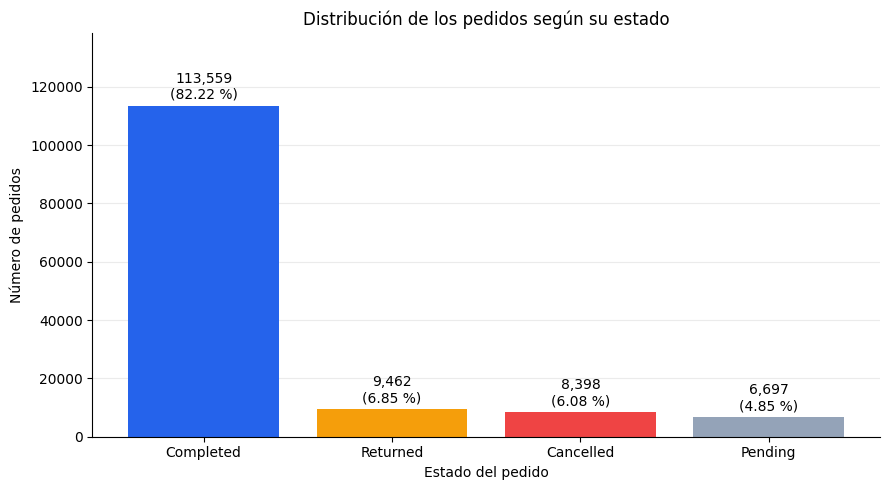

In [17]:
# Distribución del estado de los pedidos
tabla_estados = (
    df_analisis["order_status"]
    .value_counts(dropna=False)
    .rename_axis("Estado del pedido")
    .to_frame("Frecuencia")
)

tabla_estados["Porcentaje"] = (tabla_estados["Frecuencia"] / len(df_analisis) * 100)

display(tabla_estados.round(2))

# Gráfico de barras
fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.bar(
    tabla_estados.index.astype(str),
    tabla_estados["Frecuencia"],
    color=["#2563EB", "#F59E0B", "#EF4444", "#94A3B8"]
)

# Mostrar frecuencia y porcentaje sobre cada barra
for barra, frecuencia, porcentaje in zip(
    barras,
    tabla_estados["Frecuencia"],
    tabla_estados["Porcentaje"]
):
    ax.annotate(
        f"{frecuencia:,.0f}\n({porcentaje:.2f} %)",
        xy=(barra.get_x() + barra.get_width() / 2, barra.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

ax.set_title("Distribución de los pedidos según su estado")
ax.set_xlabel("Estado del pedido")
ax.set_ylabel("Número de pedidos")
ax.set_ylim(0, tabla_estados["Frecuencia"].max() * 1.22)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)

for borde in ["top", "right"]:
    ax.spines[borde].set_visible(False)

plt.tight_layout()
plt.show()

**Interpretación.**

Los pedidos completados (`Completed`) representan el **82,22 %** del total,
mientras que los devueltos (`Returned`) corresponden al **6,85 %**. Los estados
cancelado y pendiente representan el **6,08 %** y el **4,85 %**, respectivamente.

La distribución muestra un predominio de pedidos completados. Para la futura
clasificación entre pedidos completados y devueltos, será necesario considerar
el desbalance de clases y evaluar métricas como sensibilidad, precisión y F1,
además de la exactitud.

#### 6.1.2 Valor neto de venta (`net_sales`, USD)

,Valor
Número de pedidos,"82,600.000"
Media (USD),"1,237.652"
Mediana (USD),915.620
Desviación estándar (USD),"1,128.656"
Varianza (USD²),"1,273,863.996"
Mínimo (USD),5.800
Primer cuartil (USD),432.370
Tercer cuartil (USD),"1,684.542"
Máximo (USD),"16,218.000"
Rango (USD),"16,212.200"


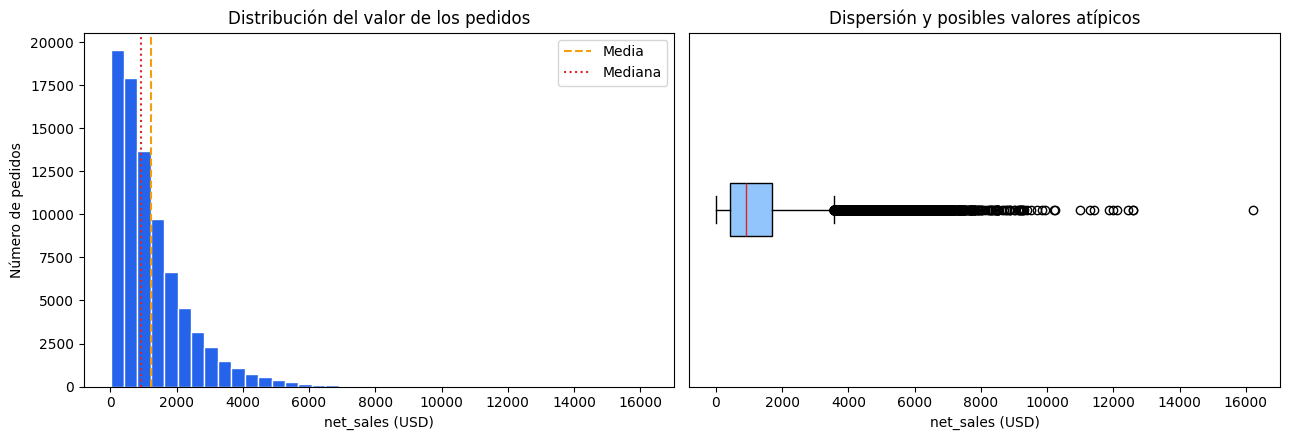

In [18]:
# Seleccionar los importes registrados en USD
ventas_usd = df_analisis.loc[df_analisis["currency"].eq("USD"),"net_sales"].dropna()

if ventas_usd.empty:
    raise ValueError("No se encontraron valores de net_sales en USD.")

# Identificar posibles valores atípicos mediante la regla IQR
q1, q3 = ventas_usd.quantile([0.25, 0.75])
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

atipicos_ventas = (
    (ventas_usd < limite_inferior) |
    (ventas_usd > limite_superior)
)

# Estadísticas descriptivas
resumen_ventas = pd.Series({
    "Número de pedidos": ventas_usd.count(),
    "Media (USD)": ventas_usd.mean(),
    "Mediana (USD)": ventas_usd.median(),
    "Desviación estándar (USD)": ventas_usd.std(),
    "Varianza (USD²)": ventas_usd.var(),
    "Mínimo (USD)": ventas_usd.min(),
    "Primer cuartil (USD)": q1,
    "Tercer cuartil (USD)": q3,
    "Máximo (USD)": ventas_usd.max(),
    "Rango (USD)": ventas_usd.max() - ventas_usd.min(),
    "Rango intercuartílico (USD)": iqr,
    "Asimetría": ventas_usd.skew(),
    "Curtosis (exceso)": ventas_usd.kurt(),
    "Posibles atípicos (IQR)": atipicos_ventas.sum(),
    "Porcentaje de posibles atípicos": atipicos_ventas.mean() * 100
}).to_frame("Valor")

display(resumen_ventas.round(3))

# Histograma y diagrama de caja
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(
    ventas_usd,
    bins=40,
    color="#2563EB",
    edgecolor="white"
)
axes[0].axvline(
    ventas_usd.mean(),
    color="#F59E0B",
    linestyle="--",
    label="Media"
)
axes[0].axvline(
    ventas_usd.median(),
    color="#DC2626",
    linestyle=":",
    label="Mediana"
)
axes[0].set_title("Distribución del valor de los pedidos")
axes[0].set_xlabel("net_sales (USD)")
axes[0].set_ylabel("Número de pedidos")
axes[0].legend()

axes[1].boxplot(
    ventas_usd,
    vert=False,
    whis=1.5,
    patch_artist=True,
    boxprops={"facecolor": "#93C5FD"},
    medianprops={"color": "#DC2626"}
)
axes[1].set_title("Dispersión y posibles valores atípicos")
axes[1].set_xlabel("net_sales (USD)")
axes[1].set_yticks([])

plt.tight_layout()
plt.show()

**Análisis e interpretación.**

Se analizaron **82.600 pedidos en USD**. La venta neta media fue de **1.237,65 USD**, frente a una mediana de **915,62 USD**. La diferencia, junto con una asimetría de **1,921**, indica una cola hacia importes elevados; la media no representa por sí sola el pedido típico.

La regla de **1,5 × IQR** identifica **3.882 posibles valores atípicos (4,70 %)**. No constituyen errores automáticamente: conviene contrastarlos con descuentos, cantidades y características de los pedidos antes de decidir un tratamiento en la Fase 2.

#### 6.1.3 Cantidad de unidades por pedido

,Frecuencia,Porcentaje
Unidades por pedido,,
1,11363,8.230
2,14627,10.590
3,16889,12.230
4,17101,12.380
5,16126,11.680
6,14144,10.240
7,11969,8.670
8,9823,7.110
9,7505,5.430


,Valor
Número de pedidos,"138,116.000"
Media,5.615
Mediana,5.000
Desviación estándar,3.371
Varianza,11.366
Mínimo,1.000
Primer cuartil,3.000
Tercer cuartil,8.000
Máximo,24.000
Rango,23.000


Moda(s): 4 unidades


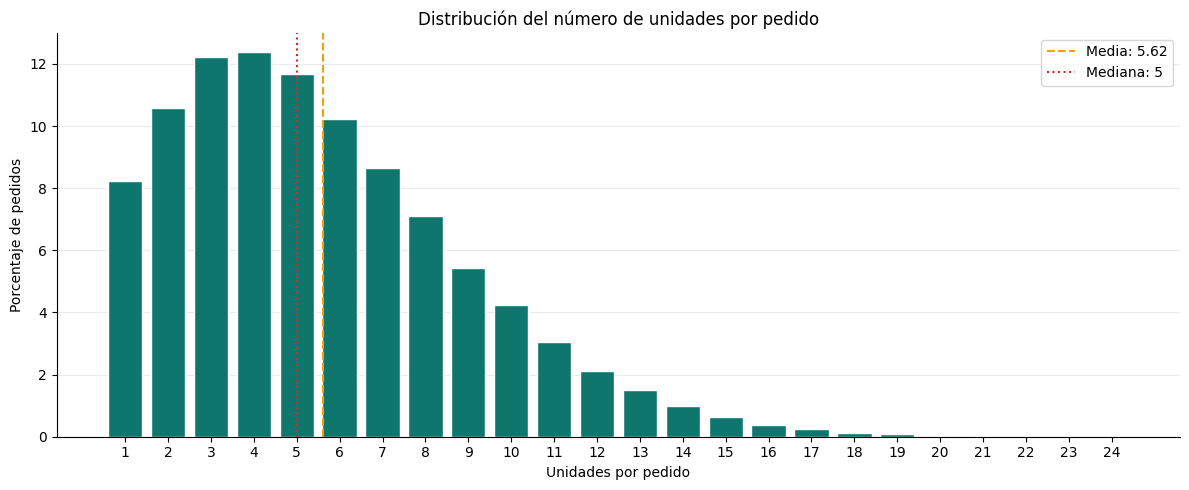

In [19]:
# Número de unidades por pedido
unidades_pedido = df_analisis["quantity"].dropna()

# Tabla de frecuencias
tabla_cantidades = (unidades_pedido.value_counts().sort_index().rename_axis("Unidades por pedido").to_frame("Frecuencia"))

tabla_cantidades["Porcentaje"] = (tabla_cantidades["Frecuencia"] / len(unidades_pedido) * 100)

display(tabla_cantidades.round(2))

# Estadísticas descriptivas
modas_cantidad = unidades_pedido.mode()
q1_cantidad, q3_cantidad = unidades_pedido.quantile([0.25, 0.75])

resumen_cantidades = pd.Series({
    "Número de pedidos": unidades_pedido.count(),
    "Media": unidades_pedido.mean(),
    "Mediana": unidades_pedido.median(),
    "Desviación estándar": unidades_pedido.std(),
    "Varianza": unidades_pedido.var(),
    "Mínimo": unidades_pedido.min(),
    "Primer cuartil": q1_cantidad,
    "Tercer cuartil": q3_cantidad,
    "Máximo": unidades_pedido.max(),
    "Rango": unidades_pedido.max() - unidades_pedido.min(),
    "Rango intercuartílico": q3_cantidad - q1_cantidad,
    "Asimetría": unidades_pedido.skew(),
    "Curtosis (exceso)": unidades_pedido.kurt()
}).to_frame("Valor")

display(resumen_cantidades.round(3))

texto_modas = ", ".join(f"{valor:g}" for valor in modas_cantidad)
print("Moda(s):", texto_modas, "unidades")

# Gráfico de barras para una variable discreta
fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(tabla_cantidades.index, tabla_cantidades["Porcentaje"], color="#0F766E", edgecolor="white")
ax.axvline(unidades_pedido.mean(),color="#F59E0B", linestyle="--", label=f"Media: {unidades_pedido.mean():.2f}")
ax.axvline(unidades_pedido.median(), color="#DC2626", linestyle=":", label=f"Mediana: {unidades_pedido.median():g}")

ax.set_title("Distribución del número de unidades por pedido")
ax.set_xlabel("Unidades por pedido")
ax.set_ylabel("Porcentaje de pedidos")
ax.set_xticks(tabla_cantidades.index)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.legend()

for borde in ["top", "right"]:
    ax.spines[borde].set_visible(False)

plt.tight_layout()
plt.show()

**Análisis e interpretación.**

Los pedidos contienen en promedio **5,62 unidades**, con una mediana de **5 unidades**. La cantidad más frecuente es de **4 unidades**.

La cantidad registrada varía entre **1** y **24 unidades**, con una desviación estándar de **3,37 unidades**. Esta variable permite caracterizar el tamaño de la compra; posteriormente se evaluará su asociación con el valor del pedido mediante el análisis bivariado.

#### 6.1.4 Edad de los clientes

,Valor
Número de clientes únicos,"24,911.000"
Media (años),45.917
Mediana (años),46.000
Desviación estándar (años),16.450
Varianza (años²),270.609
Mínimo (años),18.000
Primer cuartil (años),32.000
Tercer cuartil (años),60.000
Máximo (años),74.000
Rango (años),56.000


Moda(s): 19 años


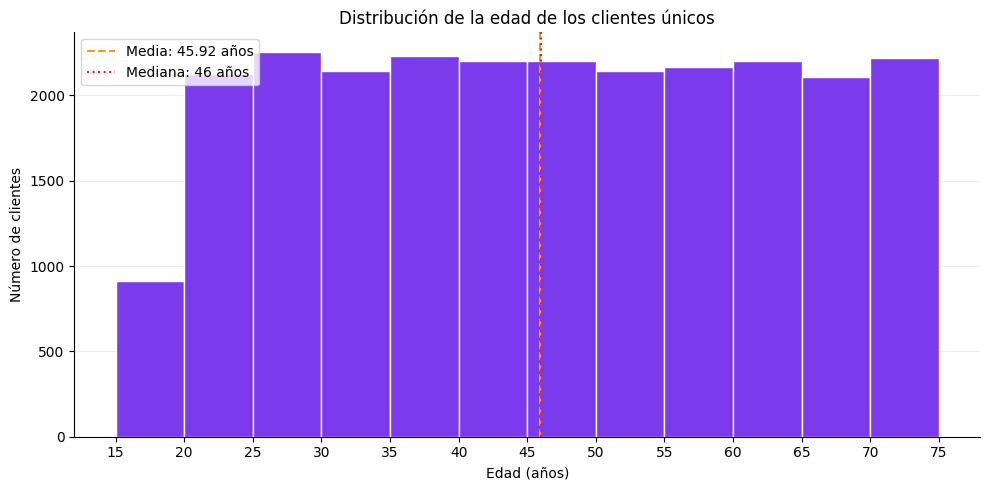

In [20]:
# Comprobar si cada cliente tiene una única edad registrada
edades_por_cliente = (df_analisis.groupby("customer_id")["customer_age"].nunique())

if edades_por_cliente.gt(1).any():
    raise ValueError(
        "Hay clientes con diferentes edades registradas. "
        "Revisa si corresponden a cambios temporales o inconsistencias.")

# Seleccionar clientes únicos con edad disponible
edades_clientes = (
    df_analisis[["customer_id", "customer_age"]]
    .dropna(subset=["customer_id", "customer_age"])
    .drop_duplicates(subset="customer_id")
    ["customer_age"]
)

if edades_clientes.empty:
    raise ValueError("No hay edades disponibles para analizar.")

# Estadísticas descriptivas
q1_edad, q3_edad = edades_clientes.quantile([0.25, 0.75])
modas_edad = edades_clientes.mode()
texto_modas_edad = ", ".join(f"{edad:g}" for edad in modas_edad)

resumen_edades = pd.Series({
    "Número de clientes únicos": edades_clientes.count(),
    "Media (años)": edades_clientes.mean(),
    "Mediana (años)": edades_clientes.median(),
    "Desviación estándar (años)": edades_clientes.std(),
    "Varianza (años²)": edades_clientes.var(),
    "Mínimo (años)": edades_clientes.min(),
    "Primer cuartil (años)": q1_edad,
    "Tercer cuartil (años)": q3_edad,
    "Máximo (años)": edades_clientes.max(),
    "Rango (años)": edades_clientes.max() - edades_clientes.min(),
    "Rango intercuartílico (años)": q3_edad - q1_edad,
    "Asimetría": edades_clientes.skew(),
    "Curtosis (exceso)": edades_clientes.kurt()
}).to_frame("Valor")

display(resumen_edades.round(3))
print("Moda(s):", texto_modas_edad, "años")

# Histograma con intervalos de cinco años
inicio_edad = int(edades_clientes.min() // 5) * 5
fin_edad = (int(edades_clientes.max() // 5) + 1) * 5
intervalos_edad = np.arange(inicio_edad, fin_edad + 5, 5)

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(edades_clientes, bins=intervalos_edad, color="#7C3AED", edgecolor="white")

ax.axvline(edades_clientes.mean(), color="#F59E0B", linestyle="--", label=f"Media: {edades_clientes.mean():.2f} años")
ax.axvline( edades_clientes.median(), color="#DC2626", linestyle=":", label=f"Mediana: {edades_clientes.median():g} años")

ax.set_title("Distribución de la edad de los clientes únicos")
ax.set_xlabel("Edad (años)")
ax.set_ylabel("Número de clientes")
ax.set_xticks(intervalos_edad)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.legend()

for borde in ["top", "right"]:
    ax.spines[borde].set_visible(False)

plt.tight_layout()
plt.show()

**Análisis e interpretación.**

Se analizaron **24.911 clientes únicos**, con una edad media de **45,92 años** y una mediana de **46 años**. Las edades registradas varían entre **18** y **74 años**.

El intervalo intercuartílico se extiende desde **32** hasta **60 años**, con una amplitud de **28 años**. Al contar cada cliente una sola vez, la distribución describe la composición etaria de los clientes presentes en la base, sin dar mayor peso a quienes realizaron más pedidos.

#### 6.1.5 Sentimiento de las reseñas

,Frecuencia,Porcentaje válido,Porcentaje acumulado
Sentimiento,,,
Negative,792,0.700,0.700
Neutral,34684,30.540,31.240
Positive,78083,68.760,100.000


Reseñas registradas: 113,559
Sentimientos faltantes: 24,557 (17.78 % del total de pedidos)


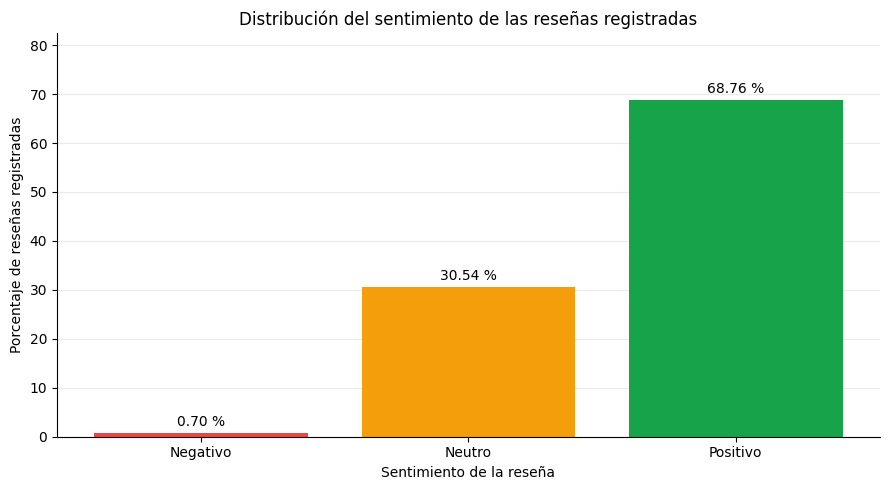

In [21]:
# Seleccionar las reseñas con sentimiento registrado
orden_sentimiento = ["Negative", "Neutral", "Positive"]
sentimientos_validos = df_analisis["review_sentiment"].dropna()

if sentimientos_validos.empty:
    raise ValueError("No hay sentimientos registrados para analizar.")

# Tabla de frecuencias respetando el orden ordinal
tabla_sentimiento_eda = (
    sentimientos_validos.value_counts(sort=False)
    .reindex(orden_sentimiento, fill_value=0)
    .rename_axis("Sentimiento")
    .to_frame("Frecuencia")
)

tabla_sentimiento_eda["Porcentaje válido"] = (tabla_sentimiento_eda["Frecuencia"] / len(sentimientos_validos) * 100)

tabla_sentimiento_eda["Porcentaje acumulado"] = (tabla_sentimiento_eda["Porcentaje válido"].cumsum())

display(tabla_sentimiento_eda.round(2))

# Reportar los faltantes por separado
faltantes_sentimiento = df_analisis["review_sentiment"].isna().sum()
porcentaje_faltantes_sentimiento = (
    faltantes_sentimiento / len(df_analisis) * 100
)

print(f"Reseñas registradas: {len(sentimientos_validos):,}")
print(
    f"Sentimientos faltantes: {faltantes_sentimiento:,} "
    f"({porcentaje_faltantes_sentimiento:.2f} % del total de pedidos)"
)

# Gráfico de barras en orden ordinal
fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.bar(["Negativo", "Neutro", "Positivo"],
    tabla_sentimiento_eda["Porcentaje válido"], color=["#EF4444", "#F59E0B", "#16A34A"])

for barra, porcentaje in zip(
    barras, tabla_sentimiento_eda["Porcentaje válido"]
):
    ax.annotate(
        f"{porcentaje:.2f} %",
        xy=(barra.get_x() + barra.get_width() / 2, barra.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

ax.set_title("Distribución del sentimiento de las reseñas registradas")
ax.set_xlabel("Sentimiento de la reseña")
ax.set_ylabel("Porcentaje de reseñas registradas")
ax.margins(y=0.20)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)

for borde in ["top", "right"]:
    ax.spines[borde].set_visible(False)

plt.tight_layout()
plt.show()

**Análisis e interpretación.**

Entre las **113.559 reseñas con sentimiento registrado**, predomina la categoría **positiva**: **78.083 registros (68,76 % de las reseñas válidas)**. La categoría neutra debe mantenerse diferenciada de la ausencia de información.

Los **24.557 faltantes (17,78 % de todos los pedidos)** están asociados con estados distintos de `Completed`, de acuerdo con la comprobación previa. Por ello, la distribución del sentimiento describe **únicamente los pedidos completados**, no la satisfacción de toda la base ni el comportamiento de las devoluciones.

#### 6.1.6 Puntos de fidelización canjeados

,Valor
Número de pedidos,"138,116.000"
Media,51.934
Mediana,25.000
Desviación estándar,73.218
Varianza,"5,360.830"
Mínimo,0.000
Primer cuartil,3.000
Tercer cuartil,71.000
Máximo,"1,063.000"
Rango,"1,063.000"


Moda(s): 0 puntos


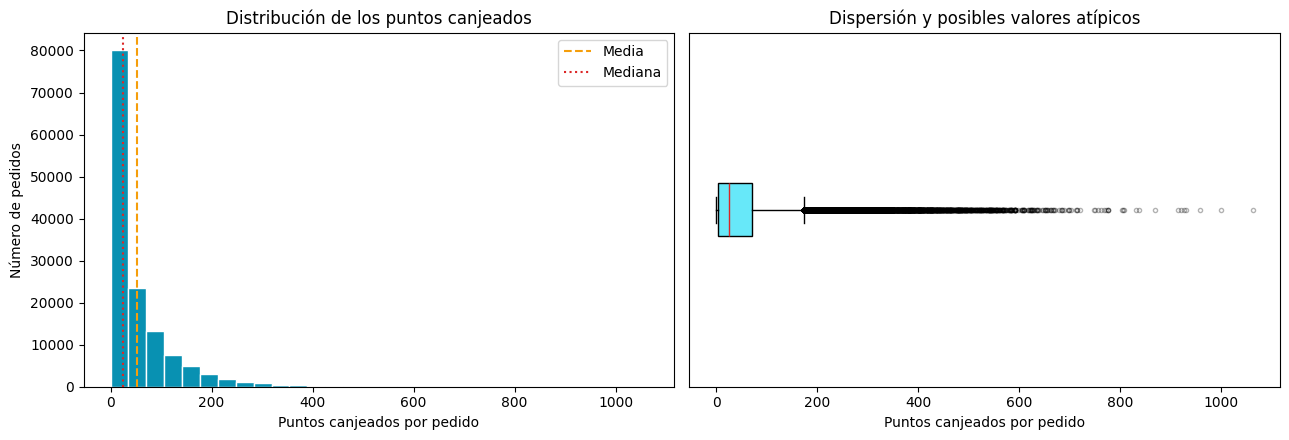

In [22]:
# Seleccionar los puntos canjeados registrados
puntos_canjeados = df_analisis["loyalty_points_redeemed"].dropna()

if puntos_canjeados.empty:
    raise ValueError("No hay datos de puntos canjeados para analizar.")

# Estadísticas descriptivas
q1_puntos, q3_puntos = puntos_canjeados.quantile([0.25, 0.75])
modas_puntos = puntos_canjeados.mode()

pedidos_sin_canje = puntos_canjeados.eq(0).sum()
porcentaje_sin_canje = puntos_canjeados.eq(0).mean() * 100

resumen_puntos = pd.Series({
    "Número de pedidos": puntos_canjeados.count(),
    "Media": puntos_canjeados.mean(),
    "Mediana": puntos_canjeados.median(),
    "Desviación estándar": puntos_canjeados.std(),
    "Varianza": puntos_canjeados.var(),
    "Mínimo": puntos_canjeados.min(),
    "Primer cuartil": q1_puntos,
    "Tercer cuartil": q3_puntos,
    "Máximo": puntos_canjeados.max(),
    "Rango": puntos_canjeados.max() - puntos_canjeados.min(),
    "Rango intercuartílico": q3_puntos - q1_puntos,
    "Asimetría": puntos_canjeados.skew(),
    "Curtosis (exceso)": puntos_canjeados.kurt(),
    "Pedidos con cero puntos canjeados": pedidos_sin_canje,
    "Porcentaje con cero puntos canjeados": porcentaje_sin_canje
}).to_frame("Valor")

display(resumen_puntos.round(3))

texto_modas_puntos = ", ".join(f"{valor:g}" for valor in modas_puntos)
print("Moda(s):", texto_modas_puntos, "puntos")

# Gráficos de distribución
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(puntos_canjeados, bins=30, color="#0891B2", edgecolor="white")
axes[0].axvline(puntos_canjeados.mean(),color="#F59E0B",linestyle="--",label="Media")
axes[0].axvline(puntos_canjeados.median(), color="#DC2626",linestyle=":",label="Mediana")
axes[0].set_title("Distribución de los puntos canjeados")
axes[0].set_xlabel("Puntos canjeados por pedido")
axes[0].set_ylabel("Número de pedidos")
axes[0].legend()

axes[1].boxplot(
    puntos_canjeados,
    vert=False,
    whis=1.5,
    patch_artist=True,
    boxprops={"facecolor": "#67E8F9"},
    medianprops={"color": "#DC2626"},
    flierprops={"marker": ".", "alpha": 0.3}
)
axes[1].set_title("Dispersión y posibles valores atípicos")
axes[1].set_xlabel("Puntos canjeados por pedido")
axes[1].set_yticks([])

plt.tight_layout()
plt.show()

**Análisis e interpretación.**

El canje promedio es de **51,93 puntos por pedido**, con una mediana de **25 puntos**. Los valores registrados varían entre **0** y **1063 puntos**.

Un total de **27.155 pedidos** (**19,66 %** de los registros válidos) presenta **cero puntos canjeados**. Este valor indica que no se utilizaron puntos en esos pedidos y debe conservarse como una observación válida.

El diagrama de caja permite identificar pedidos con cantidades de puntos alejadas del intervalo central, que se revisarán en el diagnóstico de valores atípicos.

#### 6.1.7 Plazo estimado de entrega

Tipo de variable: Cuantitativa discreta


,Valor
Número de pedidos,"113,559.000"
Media (días),4.299
Mediana (días),4.000
Desviación estándar (días),2.594
Varianza (días²),6.729
Mínimo (días),0.000
Primer cuartil (días),2.000
Tercer cuartil (días),6.000
Máximo (días),10.000
Rango (días),10.000


Moda(s): 3 días


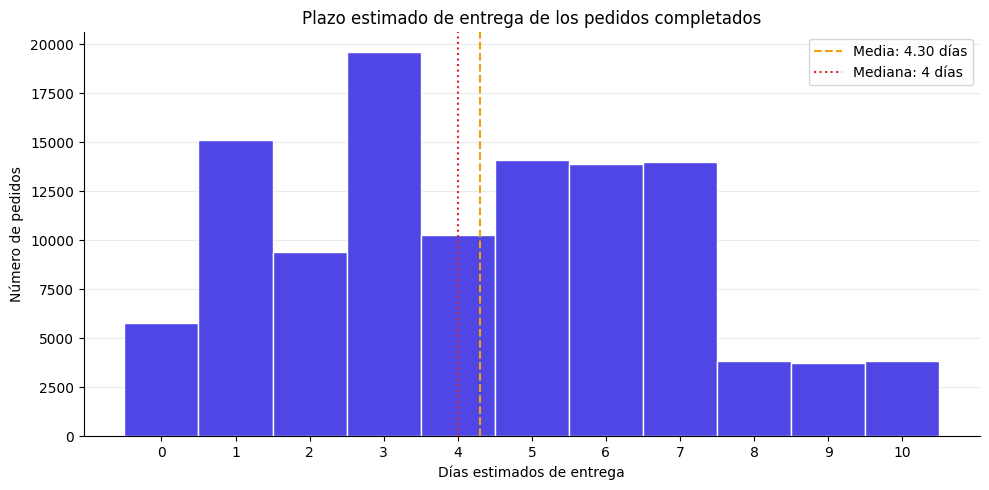

In [23]:
# Seleccionar pedidos completados con plazo estimado registrado
dias_estimados = df_analisis.loc[
    df_analisis["order_status"].eq("Completed"),
    "estimated_delivery_days"
].dropna()

if dias_estimados.empty:
    raise ValueError("No hay plazos estimados disponibles para analizar.")

# Identificar si los días están registrados como enteros
dias_estimados_enteros = dias_estimados.mod(1).eq(0).all()

print(
    "Tipo de variable:",
    "Cuantitativa discreta" if dias_estimados_enteros
    else "Cuantitativa continua"
)

# Estadísticas descriptivas
q1_estimados, q3_estimados = dias_estimados.quantile([0.25, 0.75])
modas_estimados = dias_estimados.mode()

resumen_dias_estimados = pd.Series({
    "Número de pedidos": dias_estimados.count(),
    "Media (días)": dias_estimados.mean(),
    "Mediana (días)": dias_estimados.median(),
    "Desviación estándar (días)": dias_estimados.std(),
    "Varianza (días²)": dias_estimados.var(),
    "Mínimo (días)": dias_estimados.min(),
    "Primer cuartil (días)": q1_estimados,
    "Tercer cuartil (días)": q3_estimados,
    "Máximo (días)": dias_estimados.max(),
    "Rango (días)": dias_estimados.max() - dias_estimados.min(),
    "Rango intercuartílico (días)": q3_estimados - q1_estimados,
    "Asimetría": dias_estimados.skew(),
    "Curtosis (exceso)": dias_estimados.kurt()
}).to_frame("Valor")

display(resumen_dias_estimados.round(3))

texto_modas_estimados = ", ".join(
    f"{valor:g}" for valor in modas_estimados
)
print("Moda(s):", texto_modas_estimados, "días")

# Usar intervalos de un día cuando los registros sean enteros
if dias_estimados_enteros:
    intervalos_estimados = np.arange(
        dias_estimados.min() - 0.5,
        dias_estimados.max() + 1.5,
        1
    )
else:
    intervalos_estimados = 30

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    dias_estimados,
    bins=intervalos_estimados,
    color="#4F46E5",
    edgecolor="white"
)
ax.axvline(
    dias_estimados.mean(),
    color="#F59E0B",
    linestyle="--",
    label=f"Media: {dias_estimados.mean():.2f} días"
)
ax.axvline(
    dias_estimados.median(),
    color="#DC2626",
    linestyle=":",
    label=f"Mediana: {dias_estimados.median():g} días"
)

ax.set_title("Plazo estimado de entrega de los pedidos completados")
ax.set_xlabel("Días estimados de entrega")
ax.set_ylabel("Número de pedidos")
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.legend()

if dias_estimados.nunique() <= 20:
    ax.set_xticks(sorted(dias_estimados.unique()))

for borde in ["top", "right"]:
    ax.spines[borde].set_visible(False)

plt.tight_layout()
plt.show()

**Análisis e interpretación.**

Se analizaron **113.559 pedidos completados** con plazo estimado registrado. La estimación media es de **4,30 días**, con una mediana de **4 días**. Los plazos observados varían entre **0** y **10 días**.

El intervalo intercuartílico se extiende desde **2** hasta **6 días**. Estos resultados describen exclusivamente los pedidos completados, porque los demás estados carecen de esta información.

El cumplimiento de los plazos se evaluará posteriormente mediante la comparación con los días reales de entrega (`delivery_days`).

#### 6.1.8 Tiempo real de entrega

,Valor
Número de pedidos,"113,559.000"
Media (días),4.558
Mediana (días),4.000
Desviación estándar (días),2.810
Varianza (días²),7.896
Mínimo (días),0.000
Primer cuartil (días),2.000
Tercer cuartil (días),7.000
Máximo (días),14.000
Rango (días),14.000


Moda(s): 3 días


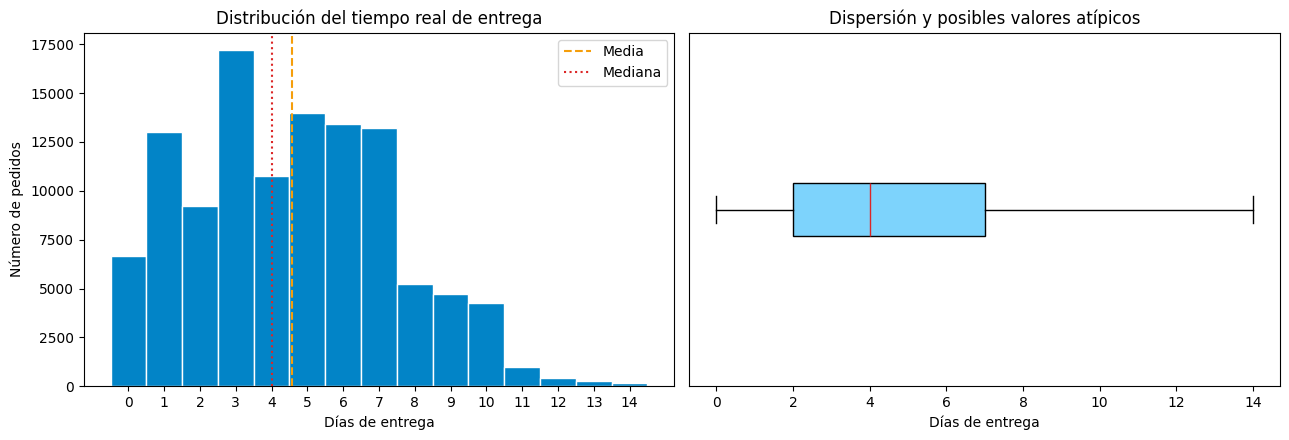

In [24]:
# Seleccionar los tiempos de entrega de pedidos completados
dias_reales = df_analisis.loc[
    df_analisis["order_status"].eq("Completed"),
    "delivery_days"
].dropna()

if dias_reales.empty:
    raise ValueError("No hay tiempos de entrega disponibles para analizar.")

# Estadísticas y límites para identificar posibles atípicos
q1_reales, q3_reales = dias_reales.quantile([0.25, 0.75])
iqr_reales = q3_reales - q1_reales

limite_inferior_reales = q1_reales - 1.5 * iqr_reales
limite_superior_reales = q3_reales + 1.5 * iqr_reales

atipicos_dias_reales = (
    (dias_reales < limite_inferior_reales) |
    (dias_reales > limite_superior_reales)
)

resumen_dias_reales = pd.Series({
    "Número de pedidos": dias_reales.count(),
    "Media (días)": dias_reales.mean(),
    "Mediana (días)": dias_reales.median(),
    "Desviación estándar (días)": dias_reales.std(),
    "Varianza (días²)": dias_reales.var(),
    "Mínimo (días)": dias_reales.min(),
    "Primer cuartil (días)": q1_reales,
    "Tercer cuartil (días)": q3_reales,
    "Máximo (días)": dias_reales.max(),
    "Rango (días)": dias_reales.max() - dias_reales.min(),
    "Rango intercuartílico (días)": iqr_reales,
    "Asimetría": dias_reales.skew(),
    "Curtosis (exceso)": dias_reales.kurt(),
    "Posibles atípicos (IQR)": atipicos_dias_reales.sum(),
    "Porcentaje de posibles atípicos": atipicos_dias_reales.mean() * 100
}).to_frame("Valor")

display(resumen_dias_reales.round(3))

texto_modas_reales = ", ".join(
    f"{valor:g}" for valor in dias_reales.mode()
)
print("Moda(s):", texto_modas_reales, "días")

# Adaptar los intervalos a la precisión de los datos
if dias_reales.mod(1).eq(0).all():
    intervalos_reales = np.arange(
        dias_reales.min() - 0.5,
        dias_reales.max() + 1.5,
        1
    )
else:
    intervalos_reales = 30

# Histograma y diagrama de caja
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(
    dias_reales,
    bins=intervalos_reales,
    color="#0284C7",
    edgecolor="white"
)
axes[0].axvline(
    dias_reales.mean(),
    color="#F59E0B",
    linestyle="--",
    label="Media"
)
axes[0].axvline(
    dias_reales.median(),
    color="#DC2626",
    linestyle=":",
    label="Mediana"
)
axes[0].set_title("Distribución del tiempo real de entrega")
axes[0].set_xlabel("Días de entrega")
axes[0].set_ylabel("Número de pedidos")
axes[0].legend()

if dias_reales.nunique() <= 20:
    axes[0].set_xticks(sorted(dias_reales.unique()))

axes[1].boxplot(
    dias_reales,
    vert=False,
    whis=1.5,
    patch_artist=True,
    boxprops={"facecolor": "#7DD3FC"},
    medianprops={"color": "#DC2626"},
    flierprops={"marker": ".", "alpha": 0.3}
)
axes[1].set_title("Dispersión y posibles valores atípicos")
axes[1].set_xlabel("Días de entrega")
axes[1].set_yticks([])

plt.tight_layout()
plt.show()

**Análisis e interpretación.**

Se analizaron **113.559 pedidos completados**, con un tiempo real medio de **4,56 días** y mediana de **4 días**. Los valores observados varían entre **0 y 14 días**.

La regla de **1,5 × IQR** no identifica valores atípicos en esta variable (**0 registros; 0,00 %**). Esto no implica que todos los plazos sean operativamente satisfactorios: su cumplimiento debe examinarse frente a la estimación correspondiente. La interpretación se limita a pedidos `Completed`, únicos con dato de entrega registrado.

#### 6.1.9 Canal de venta

,Frecuencia,Porcentaje válido
Canal de venta,,
Mobile App,55318,40.050
Website,48237,34.920
Marketplace,20698,14.990
Social Media,13863,10.040


Pedidos sin canal de venta registrado: 0


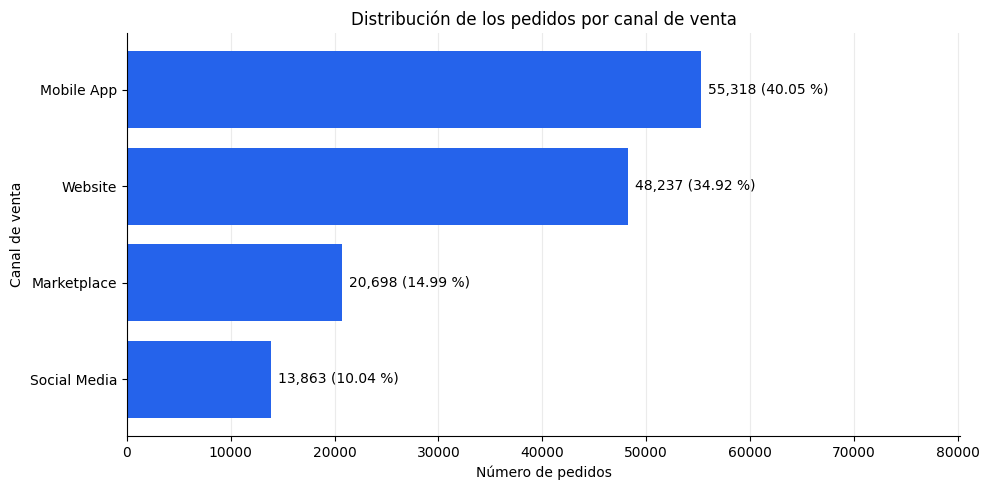

In [25]:
# Seleccionar los pedidos con canal de venta registrado
canales_venta = df_analisis["sales_channel"].dropna()

if canales_venta.empty:
    raise ValueError("No hay canales de venta registrados para analizar.")

# Tabla de frecuencias
tabla_canales = (
    canales_venta.value_counts()
    .rename_axis("Canal de venta")
    .to_frame("Frecuencia")
)

tabla_canales["Porcentaje válido"] = (
    tabla_canales["Frecuencia"] / len(canales_venta) * 100
)

display(tabla_canales.round(2))

faltantes_canales = df_analisis["sales_channel"].isna().sum()
print(f"Pedidos sin canal de venta registrado: {faltantes_canales:,}")

# Gráfico ordenado de mayor a menor frecuencia
fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.barh(
    tabla_canales.index.astype(str),
    tabla_canales["Frecuencia"],
    color="#2563EB"
)

for barra, frecuencia, porcentaje in zip(
    barras,
    tabla_canales["Frecuencia"],
    tabla_canales["Porcentaje válido"]
):
    ax.annotate(
        f"{frecuencia:,} ({porcentaje:.2f} %)",
        xy=(barra.get_width(), barra.get_y() + barra.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center"
    )

ax.invert_yaxis()
ax.set_title("Distribución de los pedidos por canal de venta")
ax.set_xlabel("Número de pedidos")
ax.set_ylabel("Canal de venta")
ax.set_xlim(0, tabla_canales["Frecuencia"].max() * 1.45)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)

for borde in ["top", "right"]:
    ax.spines[borde].set_visible(False)

plt.tight_layout()
plt.show()

**Análisis e interpretación.**

Se identificaron **4 canales de venta** en **138.116 pedidos con información registrada**. La mayor frecuencia corresponde a **Mobile App**, con **55.318 pedidos por canal** (**40,05 %**).

Esta distribución describe la participación de cada canal en el volumen de pedidos. Posteriormente se evaluará su asociación con el valor de compra y el estado del pedido mediante el análisis bivariado.

#### 6.1.10 Segmento de cliente

,Frecuencia,Porcentaje
Segmento comercial,,
Consumer,13585,54.530
Premium,6275,25.190
VIP,2536,10.180
Business,2515,10.100


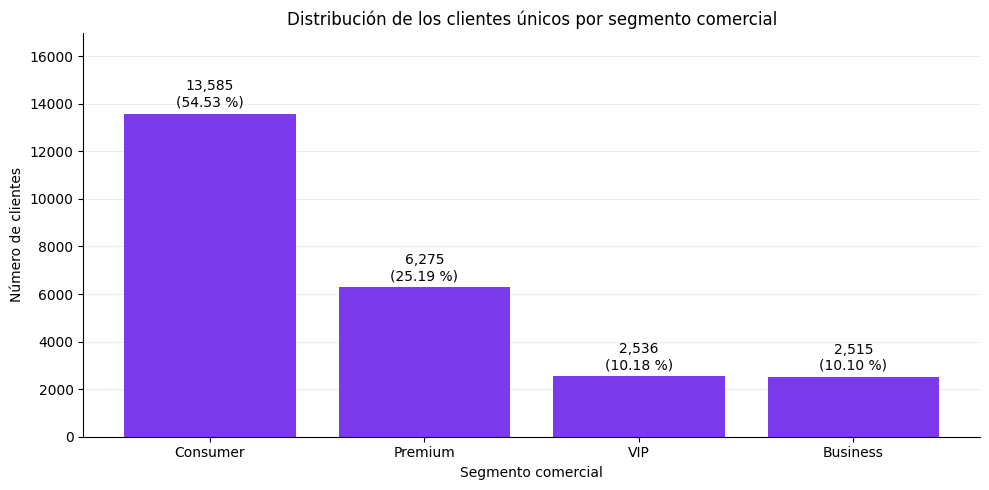

In [26]:
# Verificar si cada cliente tiene un único segmento registrado
segmentos_por_cliente = (
    df_analisis.groupby("customer_id")["customer_segment"].nunique()
)

if segmentos_por_cliente.gt(1).any():
    raise ValueError(
        "Hay clientes con varios segmentos registrados. "
        "Revisa si corresponden a cambios temporales o inconsistencias."
    )

# Seleccionar clientes únicos con segmento disponible
clientes_segmento = (
    df_analisis[["customer_id", "customer_segment"]]
    .dropna(subset=["customer_id", "customer_segment"])
    .drop_duplicates(subset="customer_id")
)

if clientes_segmento.empty:
    raise ValueError("No hay segmentos de clientes disponibles para analizar.")

# Tabla de frecuencias
tabla_segmentos = (
    clientes_segmento["customer_segment"]
    .value_counts()
    .rename_axis("Segmento comercial")
    .to_frame("Frecuencia")
)

tabla_segmentos["Porcentaje"] = (
    tabla_segmentos["Frecuencia"] / len(clientes_segmento) * 100
)

display(tabla_segmentos.round(2))

# Gráfico de barras
fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.bar(
    tabla_segmentos.index.astype(str),
    tabla_segmentos["Frecuencia"],
    color="#7C3AED"
)

for barra, frecuencia, porcentaje in zip(
    barras,
    tabla_segmentos["Frecuencia"],
    tabla_segmentos["Porcentaje"]
):
    ax.annotate(
        f"{frecuencia:,}\n({porcentaje:.2f} %)",
        xy=(barra.get_x() + barra.get_width() / 2, barra.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

ax.set_title("Distribución de los clientes únicos por segmento comercial")
ax.set_xlabel("Segmento comercial")
ax.set_ylabel("Número de clientes")
ax.set_ylim(0, tabla_segmentos["Frecuencia"].max() * 1.25)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)

for borde in ["top", "right"]:
    ax.spines[borde].set_visible(False)

plt.tight_layout()
plt.show()

**Análisis e interpretación.**

Se analizaron **24.911 clientes únicos**, distribuidos en **4 segmentos comerciales**. La mayor representación corresponde a **Consumer**, con **13.585 clientes por segmento** (**54,53 %**).

Las categorías se interpretan como perfiles comerciales nominales. Esta distribución servirá como referencia para comparar los segmentos registrados con los perfiles que se identifiquen posteriormente mediante clustering.

#### 6.1.11 País del cliente

,Frecuencia,Porcentaje
País del cliente,,
USA,14879,59.730
UK,3689,14.810
Germany,2039,8.190
Canada,1272,5.110
Australia,1226,4.920
India,1035,4.150
UAE,771,3.100


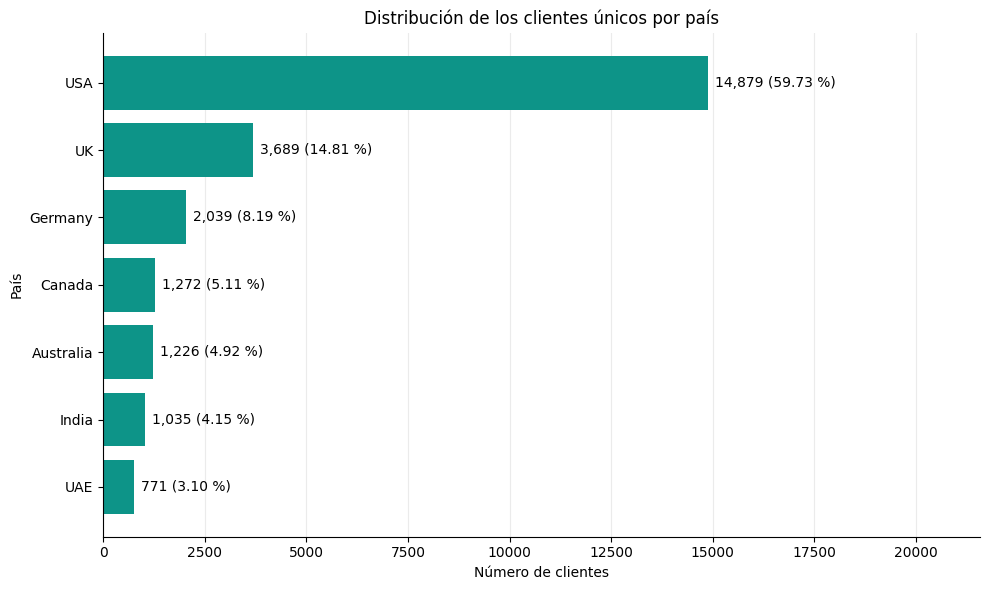

In [27]:
# Verificar si cada cliente tiene un único país registrado
paises_por_cliente = (
    df_analisis.groupby("customer_id")["customer_country"].nunique()
)

if paises_por_cliente.gt(1).any():
    raise ValueError(
        "Hay clientes con varios países registrados. "
        "Revisa si corresponden a cambios temporales o inconsistencias."
    )

# Seleccionar clientes únicos con país disponible
clientes_pais = (
    df_analisis[["customer_id", "customer_country"]]
    .dropna(subset=["customer_id", "customer_country"])
    .drop_duplicates(subset="customer_id")
)

if clientes_pais.empty:
    raise ValueError("No hay países registrados para analizar.")

# Tabla de frecuencias
tabla_paises = (
    clientes_pais["customer_country"]
    .value_counts()
    .rename_axis("País del cliente")
    .to_frame("Frecuencia")
)

tabla_paises["Porcentaje"] = (
    tabla_paises["Frecuencia"] / len(clientes_pais) * 100
)

display(tabla_paises.round(2))

# Gráfico de barras horizontales
fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(
    tabla_paises.index.astype(str),
    tabla_paises["Frecuencia"],
    color="#0D9488"
)

for barra, frecuencia, porcentaje in zip(
    barras,
    tabla_paises["Frecuencia"],
    tabla_paises["Porcentaje"]
):
    ax.annotate(
        f"{frecuencia:,} ({porcentaje:.2f} %)",
        xy=(barra.get_width(), barra.get_y() + barra.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center"
    )

ax.invert_yaxis()
ax.set_title("Distribución de los clientes únicos por país")
ax.set_xlabel("Número de clientes")
ax.set_ylabel("País")
ax.set_xlim(0, tabla_paises["Frecuencia"].max() * 1.45)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)

for borde in ["top", "right"]:
    ax.spines[borde].set_visible(False)

plt.tight_layout()
plt.show()

**Análisis e interpretación.**

Se analizaron **24.911 clientes únicos**, distribuidos en **7 países**. La mayor representación corresponde a **USA**, con **14.879 clientes por país** (**59,73 %**).

Esta distribución describe la composición geográfica de la clientela registrada y permite contextualizar las diferencias entre mercados. Cada cliente se contabilizó una sola vez.

#### 6.1.12 Método de pago

,Frecuencia,Porcentaje válido
Método de pago,,
Credit Card,41460,30.020
Debit Card,27635,20.010
PayPal,20750,15.020
Digital Wallet,16382,11.860
Cash on Delivery,13863,10.040
Buy Now Pay Later,11061,8.010
Bank Transfer,6965,5.040


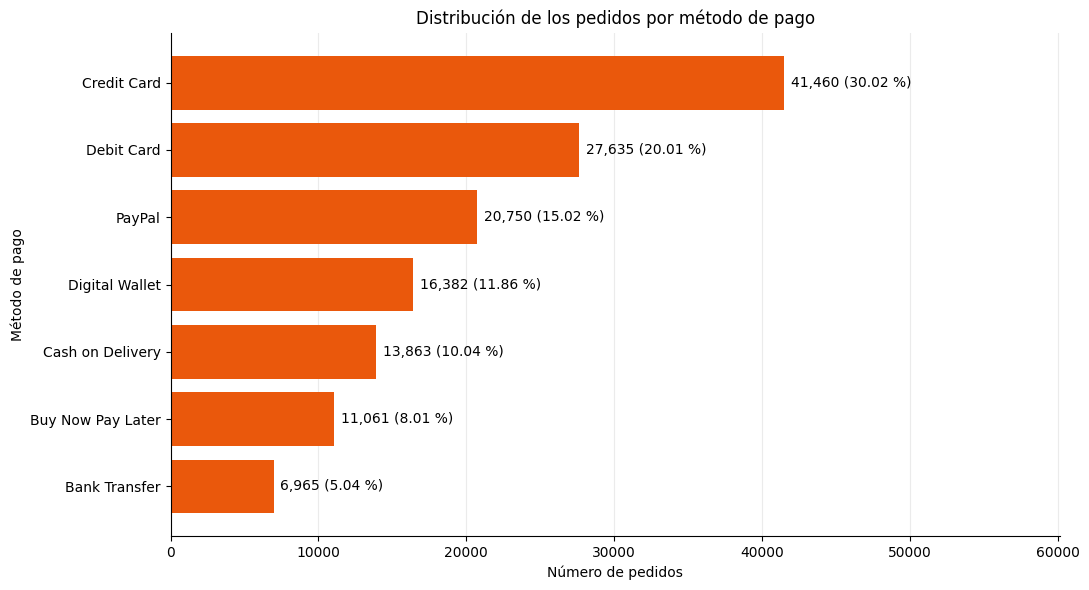

In [28]:
# Seleccionar los pedidos con método de pago registrado
metodos_pago = df_analisis["payment_method"].dropna()

if metodos_pago.empty:
    raise ValueError("No hay métodos de pago registrados para analizar.")

# Tabla de frecuencias
tabla_metodos_pago = (
    metodos_pago.value_counts()
    .rename_axis("Método de pago")
    .to_frame("Frecuencia")
)

tabla_metodos_pago["Porcentaje válido"] = (
    tabla_metodos_pago["Frecuencia"] / len(metodos_pago) * 100
)

display(tabla_metodos_pago.round(2))

# Gráfico ordenado de mayor a menor frecuencia
fig, ax = plt.subplots(figsize=(11, 6))

barras = ax.barh(
    tabla_metodos_pago.index.astype(str),
    tabla_metodos_pago["Frecuencia"],
    color="#EA580C"
)

for barra, frecuencia, porcentaje in zip(
    barras,
    tabla_metodos_pago["Frecuencia"],
    tabla_metodos_pago["Porcentaje válido"]
):
    ax.annotate(
        f"{frecuencia:,} ({porcentaje:.2f} %)",
        xy=(barra.get_width(), barra.get_y() + barra.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center"
    )

ax.invert_yaxis()
ax.set_title("Distribución de los pedidos por método de pago")
ax.set_xlabel("Número de pedidos")
ax.set_ylabel("Método de pago")
ax.set_xlim(0, tabla_metodos_pago["Frecuencia"].max() * 1.45)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)

for borde in ["top", "right"]:
    ax.spines[borde].set_visible(False)

plt.tight_layout()
plt.show()

**Análisis e interpretación.**

Se identificaron **7 métodos de pago** en **138.116 pedidos con información registrada**. La mayor frecuencia corresponde a **Credit Card**, con **41.460 pedidos por método** (**30,02 %**).

Las participaciones de los métodos de pago oscilan entre **5,04 %** y **30,02 %**. Esta distribución caracteriza el uso de las diferentes formas de pago en los pedidos registrados.

#### 6.1.13 Modalidad de envío

,Frecuencia,Porcentaje válido
Modalidad de envío,,
Standard,62006,44.890
Express,34373,24.890
Economy,27824,20.150
Same Day,13913,10.070


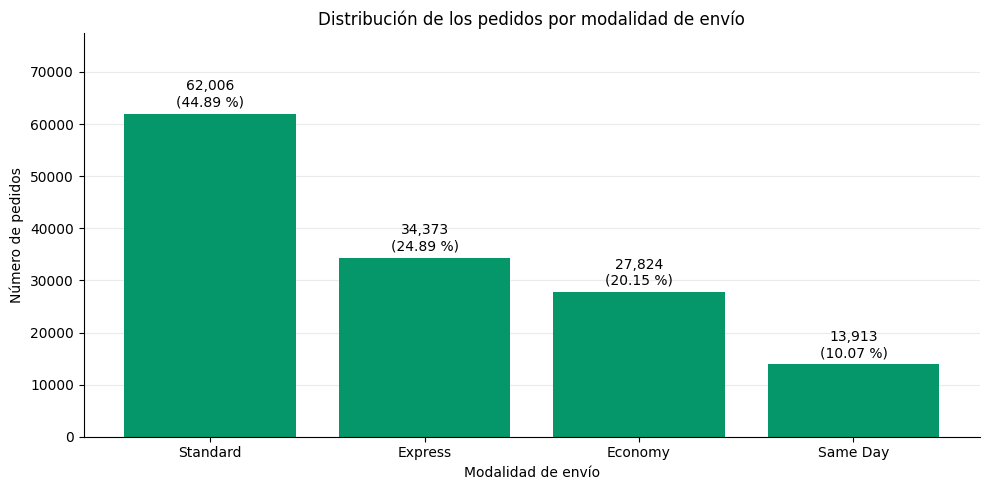

In [29]:
# Seleccionar los pedidos con modalidad de envío registrada
metodos_envio = df_analisis["shipping_method"].dropna()

if metodos_envio.empty:
    raise ValueError("No hay modalidades de envío registradas para analizar.")

# Tabla de frecuencias
tabla_metodos_envio = (
    metodos_envio.value_counts()
    .rename_axis("Modalidad de envío")
    .to_frame("Frecuencia")
)

tabla_metodos_envio["Porcentaje válido"] = (
    tabla_metodos_envio["Frecuencia"] / len(metodos_envio) * 100
)

display(tabla_metodos_envio.round(2))

# Gráfico de barras
fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.bar(
    tabla_metodos_envio.index.astype(str),
    tabla_metodos_envio["Frecuencia"],
    color="#059669"
)

for barra, frecuencia, porcentaje in zip(
    barras,
    tabla_metodos_envio["Frecuencia"],
    tabla_metodos_envio["Porcentaje válido"]
):
    ax.annotate(
        f"{frecuencia:,}\n({porcentaje:.2f} %)",
        xy=(barra.get_x() + barra.get_width() / 2, barra.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

ax.set_title("Distribución de los pedidos por modalidad de envío")
ax.set_xlabel("Modalidad de envío")
ax.set_ylabel("Número de pedidos")
ax.set_ylim(0, tabla_metodos_envio["Frecuencia"].max() * 1.25)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)

for borde in ["top", "right"]:
    ax.spines[borde].set_visible(False)

plt.tight_layout()
plt.show()

**Análisis e interpretación.**

Se identificaron **4 modalidades de envío** en **138.116 pedidos con información registrada**. La mayor frecuencia corresponde a **Standard**, con **62.006 pedidos por modalidad** (**44,89 %**).

Esta distribución describe la participación de cada modalidad en el volumen de pedidos. Su asociación con los tiempos de entrega se evaluará posteriormente en los pedidos completados con información disponible.

#### 6.1.14 Canal de marketing

,Frecuencia,Porcentaje válido
Canal de marketing,,
Organic Search,27742,20.090
Google Ads,20633,14.940
Direct,20515,14.850
Facebook Ads,16651,12.060
Instagram,13801,9.990
Email Marketing,11218,8.120
Referral,11191,8.100
Affiliate,6848,4.960
TikTok,5437,3.940


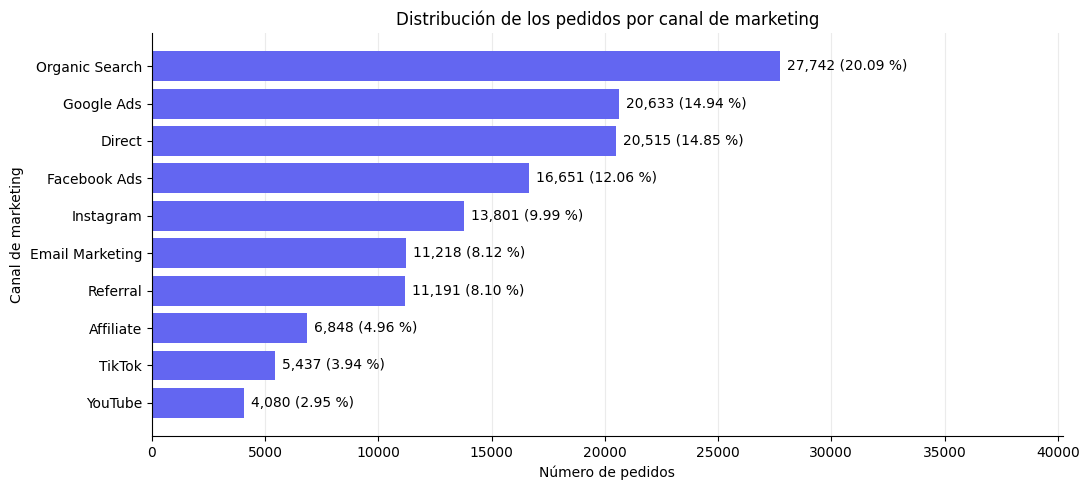

In [30]:
# Seleccionar pedidos con canal de marketing registrado
canales_marketing = df_analisis["marketing_channel"].dropna()

if canales_marketing.empty:
    raise ValueError("No hay canales de marketing registrados para analizar.")

# Tabla de frecuencias
tabla_marketing = (
    canales_marketing.value_counts()
    .rename_axis("Canal de marketing")
    .to_frame("Frecuencia")
)

tabla_marketing["Porcentaje válido"] = (
    tabla_marketing["Frecuencia"] / len(canales_marketing) * 100
)

display(tabla_marketing.round(2))

# Ajustar la altura según el número de categorías
altura_marketing = max(5, 0.45 * len(tabla_marketing))

fig, ax = plt.subplots(figsize=(11, altura_marketing))

barras = ax.barh(
    tabla_marketing.index.astype(str),
    tabla_marketing["Frecuencia"],
    color="#6366F1"
)

for barra, frecuencia, porcentaje in zip(
    barras,
    tabla_marketing["Frecuencia"],
    tabla_marketing["Porcentaje válido"]
):
    ax.annotate(
        f"{frecuencia:,} ({porcentaje:.2f} %)",
        xy=(barra.get_width(), barra.get_y() + barra.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center"
    )

ax.invert_yaxis()
ax.set_title("Distribución de los pedidos por canal de marketing")
ax.set_xlabel("Número de pedidos")
ax.set_ylabel("Canal de marketing")
ax.set_xlim(0, tabla_marketing["Frecuencia"].max() * 1.45)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)

for borde in ["top", "right"]:
    ax.spines[borde].set_visible(False)

plt.tight_layout()
plt.show()

**Análisis e interpretación.**

Se identificaron **10 canales de marketing** en **138.116 pedidos con información registrada**. La mayor frecuencia corresponde a **Organic Search**, con **27.742 pedidos por canal** (**20,09 %**).

Los **3 canales con mayor frecuencia** reúnen el **49,88 %** de los pedidos analizados. Estos resultados describen la participación de los canales de marketing en el volumen de pedidos registrado.

#### 6.1.15 Moneda del pedido

,Frecuencia,Porcentaje válido
Moneda,,
USD,82600,59.800
GBP,20235,14.650
EUR,11593,8.390
CAD,7015,5.080
AUD,6794,4.920
INR,5707,4.130
AED,4172,3.020


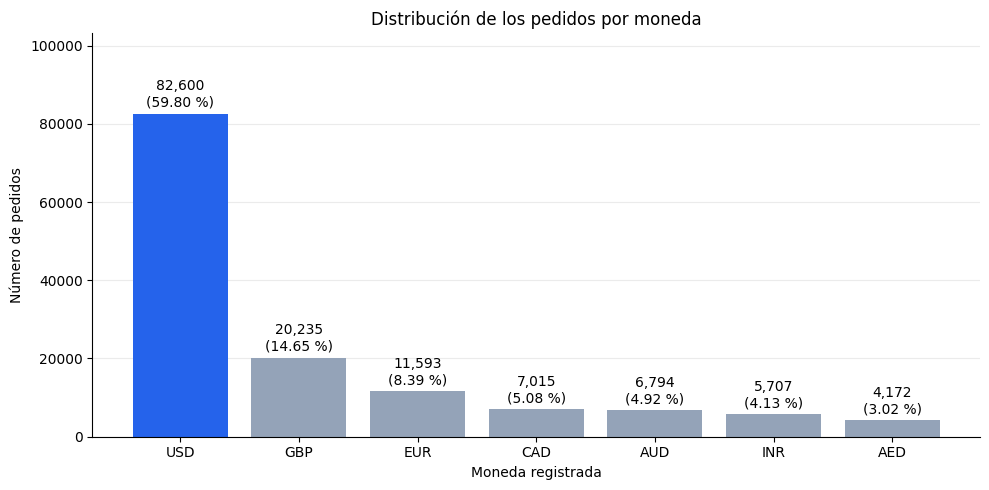

In [31]:
# Seleccionar pedidos con moneda registrada
monedas_pedido = df_analisis["currency"].dropna()

if monedas_pedido.empty:
    raise ValueError("No hay monedas registradas para analizar.")

# Tabla de frecuencias
tabla_monedas = (
    monedas_pedido.value_counts()
    .rename_axis("Moneda")
    .to_frame("Frecuencia")
)

tabla_monedas["Porcentaje válido"] = (
    tabla_monedas["Frecuencia"] / len(monedas_pedido) * 100
)

display(tabla_monedas.round(2))

# Destacar USD, la moneda seleccionada para el análisis monetario
colores_monedas = [
    "#2563EB" if moneda == "USD" else "#94A3B8"
    for moneda in tabla_monedas.index
]

fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.bar(
    tabla_monedas.index.astype(str),
    tabla_monedas["Frecuencia"],
    color=colores_monedas
)

for barra, frecuencia, porcentaje in zip(
    barras,
    tabla_monedas["Frecuencia"],
    tabla_monedas["Porcentaje válido"]
):
    ax.annotate(
        f"{frecuencia:,}\n({porcentaje:.2f} %)",
        xy=(barra.get_x() + barra.get_width() / 2, barra.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

ax.set_title("Distribución de los pedidos por moneda")
ax.set_xlabel("Moneda registrada")
ax.set_ylabel("Número de pedidos")
ax.set_ylim(0, tabla_monedas["Frecuencia"].max() * 1.25)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)

for borde in ["top", "right"]:
    ax.spines[borde].set_visible(False)

plt.tight_layout()
plt.show()

**Análisis e interpretación.**

Se identificaron **7 monedas** en **138.116 pedidos con información registrada**. Los pedidos denominados en **USD** corresponden a **82.600 registros**, equivalentes al **59,80 %** de ese total.

De acuerdo con los objetivos del proyecto, las comparaciones monetarias se realizarán sobre el subconjunto en USD. Esto permite analizar los importes registrados en `net_sales` dentro de una misma unidad monetaria.

#### 6.1.16 Evolución mensual de los pedidos

Fechas originalmente faltantes: 0
Valores que no pudieron interpretarse como fechas: 0


,Pedidos,Porcentaje
Año,,
2021,27554,19.950
2022,27564,19.960
2023,27632,20.010
2024,27768,20.100
2025,27598,19.980


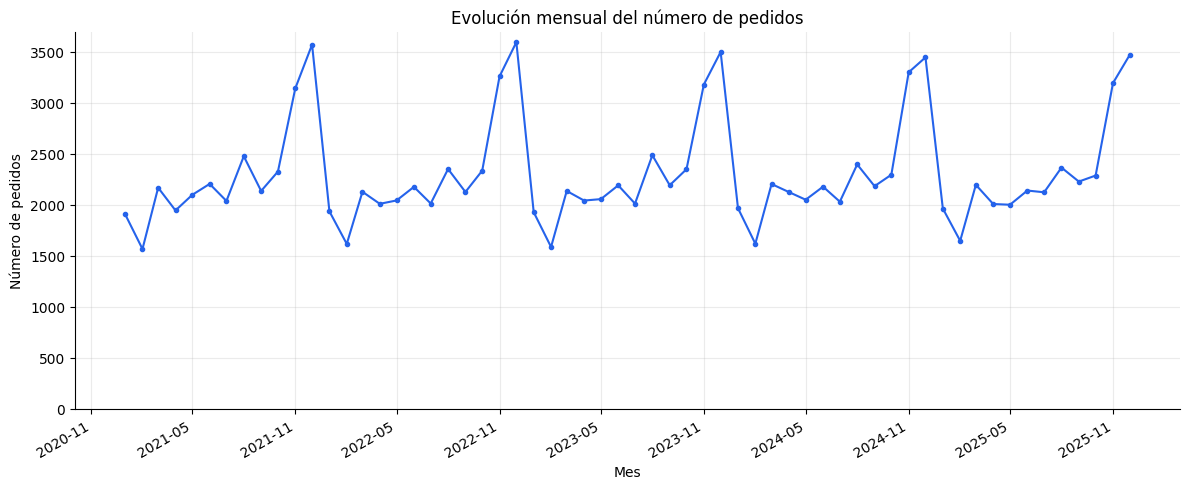

In [32]:
import matplotlib.dates as mdates

# Convertir las fechas sin modificar la columna original
fechas_pedidos = pd.to_datetime(
    df_analisis["order_date"],
    errors="coerce"
)

fechas_faltantes = df_analisis["order_date"].isna().sum()
fechas_invalidas = (
    df_analisis["order_date"].notna() & fechas_pedidos.isna()
).sum()

print(f"Fechas originalmente faltantes: {fechas_faltantes:,}")
print(f"Valores que no pudieron interpretarse como fechas: {fechas_invalidas:,}")

fechas_validas = fechas_pedidos.dropna()

if fechas_validas.empty:
    raise ValueError("No hay fechas válidas para analizar.")

# Tabla de frecuencias por año
tabla_anios = (
    fechas_validas.dt.year.value_counts()
    .sort_index()
    .rename_axis("Año")
    .to_frame("Pedidos")
)

tabla_anios["Porcentaje"] = (
    tabla_anios["Pedidos"] / len(fechas_validas) * 100
)

display(tabla_anios.round(2))

# Número de pedidos por mes
pedidos_por_mes = (
    fechas_validas.dt.to_period("M")
    .value_counts()
    .sort_index()
)

# Incluir todos los meses del periodo observado
# Un cero representa un mes sin pedidos registrados en esta base.
rango_meses = pd.period_range(
    start=fechas_validas.min().to_period("M"),
    end=fechas_validas.max().to_period("M"),
    freq="M"
)

pedidos_por_mes = pedidos_por_mes.reindex(rango_meses, fill_value=0)

# Gráfico de evolución mensual
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    pedidos_por_mes.index.to_timestamp(),
    pedidos_por_mes.values,
    color="#2563EB",
    marker="o",
    markersize=3,
    linewidth=1.5
)

ax.set_title("Evolución mensual del número de pedidos")
ax.set_xlabel("Mes")
ax.set_ylabel("Número de pedidos")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.25)

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

for borde in ["top", "right"]:
    ax.spines[borde].set_visible(False)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Análisis e interpretación.**

Se analizaron **138.116 pedidos con fecha válida**, registrados entre el **01/01/2021** y el **31/12/2025**.

El promedio mensual fue de **2.301,93 pedidos**. El mayor volumen mensual observado alcanzó **3.592 pedidos**, registrado en **2022-12**.

La gráfica permite explorar variaciones temporales en el volumen registrado. Para identificar estacionalidad, será necesario comprobar si los patrones mensuales se repiten entre años.

---

### 6.2 Análisis bivariado y multivariado

#### 6.2.1 Matriz de correlaciones de Spearman

Pedidos incluidos: 67,978
Excluidos de esta matriz por valores ausentes o no finitos: 0


,customer_age,quantity,net_sales,loyalty_points_redeemed,estimated_delivery_days,delivery_days
customer_age,1.000,-0.002,-0.001,-0.001,-0.005,-0.003
quantity,-0.002,1.000,0.683,0.518,0.005,0.004
net_sales,-0.001,0.683,1.000,0.744,-0.007,-0.006
loyalty_points_redeemed,-0.001,0.518,0.744,1.000,-0.009,-0.008
estimated_delivery_days,-0.005,0.005,-0.007,-0.009,1.000,0.924
delivery_days,-0.003,0.004,-0.006,-0.008,0.924,1.000


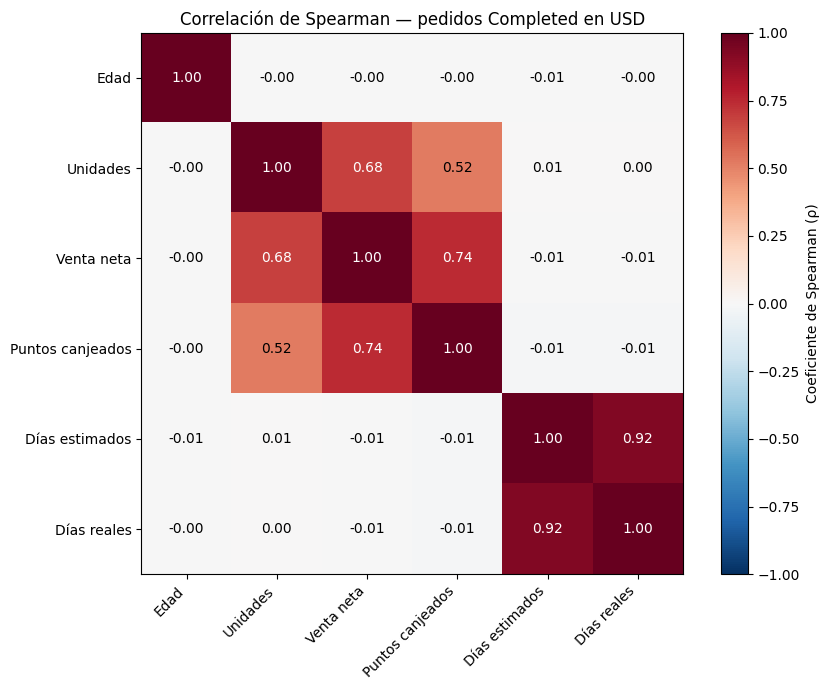

In [33]:
# Variables cuantitativas seleccionadas
variables_correlacion = [
    "customer_age",
    "quantity",
    "net_sales",
    "loyalty_points_redeemed",
    "estimated_delivery_days",
    "delivery_days"
]

# Seleccionar una población común para todas las correlaciones
base_correlacion = df_analisis.loc[
    df_analisis["currency"].eq("USD")
    & df_analisis["order_status"].eq("Completed"),
    variables_correlacion
].copy()

numero_inicial_correlacion = len(base_correlacion)

# Preparar los valores numéricos para esta matriz
base_correlacion = (
    base_correlacion
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

if len(base_correlacion) < 2:
    raise ValueError("No hay suficientes observaciones para calcular correlaciones.")

print(f"Pedidos incluidos: {len(base_correlacion):,}")
print(
    "Excluidos de esta matriz por valores ausentes o no finitos:",
    numero_inicial_correlacion - len(base_correlacion)
)

# Spearman mide asociaciones monótonas entre las variables
matriz_spearman = base_correlacion.corr(method="spearman")

display(matriz_spearman.round(3))

# Etiquetas para facilitar la lectura
nombres_correlacion = {
    "customer_age": "Edad",
    "quantity": "Unidades",
    "net_sales": "Venta neta",
    "loyalty_points_redeemed": "Puntos canjeados",
    "estimated_delivery_days": "Días estimados",
    "delivery_days": "Días reales"
}

etiquetas_correlacion = [
    nombres_correlacion[variable]
    for variable in matriz_spearman.columns
]

# Mapa de calor
fig, ax = plt.subplots(figsize=(9, 7))

imagen = ax.imshow(
    matriz_spearman,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(etiquetas_correlacion)))
ax.set_yticks(range(len(etiquetas_correlacion)))
ax.set_xticklabels(etiquetas_correlacion, rotation=45, ha="right")
ax.set_yticklabels(etiquetas_correlacion)

for fila in range(len(matriz_spearman)):
    for columna in range(len(matriz_spearman)):
        valor = matriz_spearman.iloc[fila, columna]

        texto = "NA" if pd.isna(valor) else f"{valor:.2f}"
        color = (
            "white"
            if pd.notna(valor) and abs(valor) > 0.6
            else "black"
        )

        ax.text(
            columna, fila, texto,
            ha="center", va="center",
            color=color
        )

ax.set_title("Correlación de Spearman — pedidos Completed en USD")

barra_color = fig.colorbar(imagen, ax=ax)
barra_color.set_label("Coeficiente de Spearman (ρ)")

plt.tight_layout()
plt.show()

**Análisis e interpretación.**

La matriz se calculó con **67.978 pedidos completados y denominados en USD**; ninguno de los pedidos de esa población quedó excluido por valores ausentes o no finitos en las seis variables examinadas. Se utilizó **Spearman (ρ)**, apropiado para explorar asociaciones monótonas sin exigir linealidad.

La relación más intensa con `net_sales` se observa en **`loyalty_points_redeemed` (ρ = 0,744)**, seguida de **`quantity` (ρ = 0,683)**. También se aprecia una asociación positiva entre unidades compradas y puntos canjeados (**ρ = 0,518**). Estos resultados sugieren que el importe del pedido varía conjuntamente con el volumen adquirido y el uso de puntos, aunque no permiten determinar causalidad.

Por su parte, **`estimated_delivery_days` y `delivery_days` presentan una asociación muy alta (ρ = 0,924)**. En contraste, sus correlaciones con `net_sales` son prácticamente nulas (**−0,007 y −0,006**, respectivamente), y la edad del cliente tampoco muestra una relación monótona apreciable con la venta neta (**ρ = −0,001**).

**Implicación para el modelado:** la relación entre puntos canjeados y valor de venta merece examinarse antes de seleccionar predictores: hay que comprobar cómo se generan los puntos y si se conocen en el momento de la predicción, para evitar variables que incorporen información del objetivo. Además, estas correlaciones corresponden solo a pedidos `Completed` en USD; no deben extrapolarse sin validación a otras monedas o estados.

#### 6.2.2 Diagramas de dispersión: ventas y tiempos de entrega

Pedidos disponibles: 67,978
Pedidos representados en los gráficos: 5,000


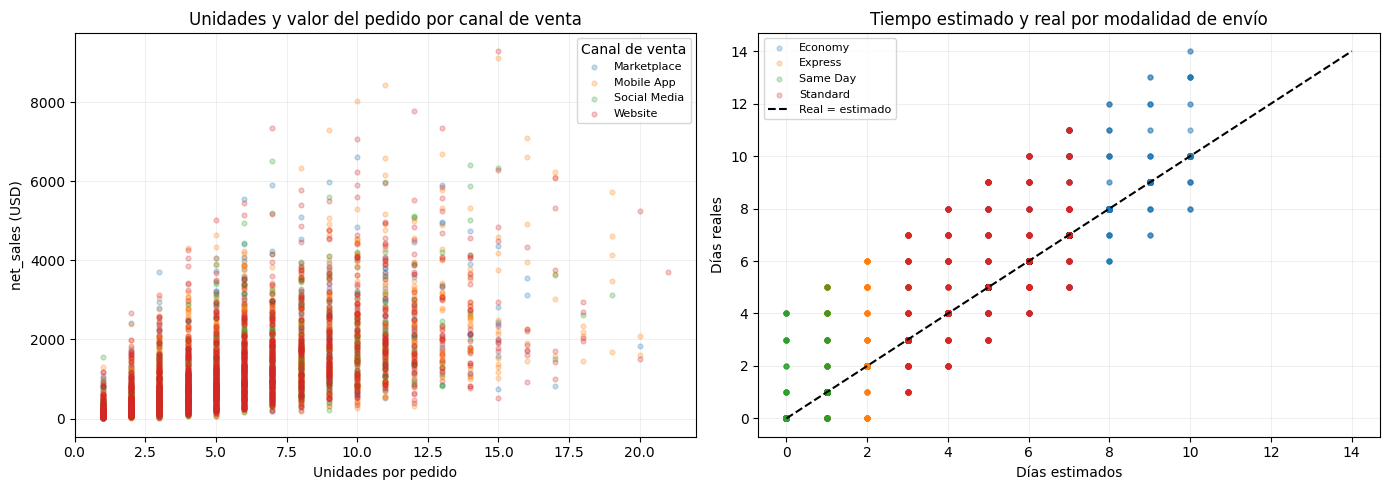

In [34]:
# Incorporar las categorías a los pedidos Completed en USD
base_dispersion = base_correlacion.join(
    df_analisis[["sales_channel", "shipping_method"]]
)

# Muestrear únicamente para dibujar; los cálculos usarán toda la base
muestra_dispersion = base_dispersion.sample(
    n=min(5000, len(base_dispersion)),
    random_state=42
)

print(f"Pedidos disponibles: {len(base_dispersion):,}")
print(f"Pedidos representados en los gráficos: {len(muestra_dispersion):,}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Unidades frente al valor del pedido, diferenciando canales
for canal, grupo in muestra_dispersion.groupby(
    "sales_channel", observed=True
):
    axes[0].scatter(
        grupo["quantity"],
        grupo["net_sales"],
        label=str(canal),
        alpha=0.25,
        s=12
    )

axes[0].set_title("Unidades y valor del pedido por canal de venta")
axes[0].set_xlabel("Unidades por pedido")
axes[0].set_ylabel("net_sales (USD)")
axes[0].legend(title="Canal de venta", fontsize=8)

# Tiempo estimado frente al real, diferenciando modalidades de envío
for modalidad, grupo in muestra_dispersion.groupby(
    "shipping_method", observed=True
):
    axes[1].scatter(
        grupo["estimated_delivery_days"],
        grupo["delivery_days"],
        label=str(modalidad),
        alpha=0.25,
        s=12
    )

limite_minimo = min(
    base_dispersion["estimated_delivery_days"].min(),
    base_dispersion["delivery_days"].min()
)
limite_maximo = max(
    base_dispersion["estimated_delivery_days"].max(),
    base_dispersion["delivery_days"].max()
)

axes[1].plot(
    [limite_minimo, limite_maximo],
    [limite_minimo, limite_maximo],
    color="black",
    linestyle="--",
    label="Real = estimado"
)

axes[1].set_title("Tiempo estimado y real por modalidad de envío")
axes[1].set_xlabel("Días estimados")
axes[1].set_ylabel("Días reales")
axes[1].legend(fontsize=8)

for ax in axes:
    ax.set_axisbelow(True)
    ax.grid(alpha=0.20)

plt.tight_layout()
plt.show()

**Análisis e interpretación.**

Los dos diagramas muestran una **muestra aleatoria reproducible de 5.000 pedidos**, extraída de **67.978 pedidos completados en USD**. Las correlaciones y proporciones comentadas se calcularon con **toda la población seleccionada**, no solo con los puntos dibujados.

**Unidades frente a venta neta.** La asociación de Spearman es **ρ = 0,683**, positiva y de magnitud apreciable: los pedidos con más unidades tienden a registrar importes mayores. No se espera, sin embargo, una correspondencia exacta, porque el precio unitario, la mezcla de productos y las condiciones comerciales también pueden modificar `net_sales`. Los colores identifican canales de venta, pero la superposición visual no constituye una prueba de diferencias entre canales.

**Plazo estimado frente a plazo real.** Se observa una asociación muy alta (**ρ = 0,924**) y una alineación general con la diagonal de igualdad. En el **15,00 %** de los pedidos el tiempo real supera el estimado; el **85,00 % restante** presenta un tiempo igual o inferior al estimado. Este porcentaje describe el subconjunto estudiado y no debe interpretarse como indicador global de puntualidad de pedidos cancelados, pendientes o devueltos, que carecen de estos datos.

**Lectura conjunta:** conviene analizar las diferencias entre días reales y estimados por modalidad de envío y comparar importes por canal controlando el tamaño del pedido. La intensidad de una correlación no mide por sí sola el error de predicción ni demuestra un efecto causal.

#### 6.2.3 Pruebas de independencia χ² y V de Cramér

,N,χ²,gl,p,V de Cramér,Mínimo esperado,Frecuencias suficientes,p ajustado,Conclusión
Variable,,,,,,,,,
sales_channel,"24,838",0.954,3,8.123e-01,0.006,188.56,True,1.000e+00,Sin evidencia suficiente
customer_segment,"24,838",2.018,3,5.687e-01,0.009,190.77,True,1.000e+00,Sin evidencia suficiente
customer_country,"24,838",9.352,6,1.547e-01,0.019,58.59,True,1.000e+00,Sin evidencia suficiente
payment_method,"24,838",3.876,6,6.934e-01,0.012,94.13,True,1.000e+00,Sin evidencia suficiente
shipping_method,"24,838",1.830,3,6.085e-01,0.009,198.30,True,1.000e+00,Sin evidencia suficiente
marketing_channel,"24,838",7.875,9,5.468e-01,0.018,54.33,True,1.000e+00,Sin evidencia suficiente
currency,"24,838",9.352,6,1.547e-01,0.019,58.59,True,1.000e+00,Sin evidencia suficiente


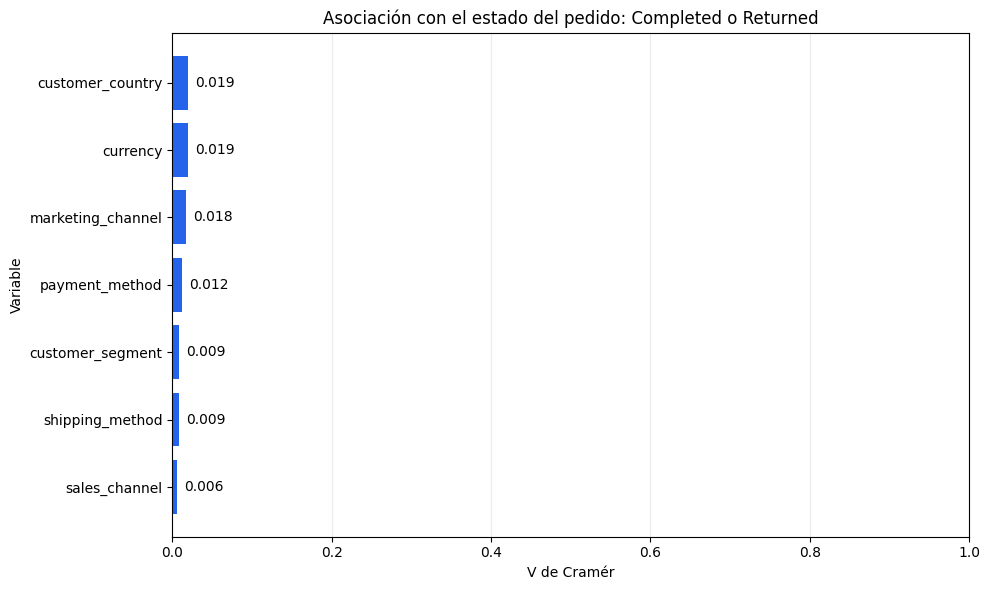

In [35]:
from scipy.stats import chi2_contingency

variables_chi2 = [
    "sales_channel",
    "customer_segment",
    "customer_country",
    "payment_method",
    "shipping_method",
    "marketing_channel",
    "currency"
]

# Seleccionar pedidos correspondientes al problema de clasificación
base_chi2 = df_analisis.loc[
    df_analisis["order_status"].isin(["Completed", "Returned"])
].dropna(subset=["customer_id"]).copy()

# Elegir un pedido aleatorio por cliente para evitar observaciones repetidas
base_chi2 = (
    base_chi2.sample(frac=1, random_state=42)
    .drop_duplicates(subset="customer_id")
)

resultados_pruebas = []
tablas_chi2 = {}

for variable in variables_chi2:
    tabla = pd.crosstab(
        base_chi2[variable],
        base_chi2["order_status"]
    )

    # Conservar categorías con observaciones
    tabla = tabla.loc[
        tabla.sum(axis=1).gt(0),
        tabla.sum(axis=0).gt(0)
    ]

    if min(tabla.shape) < 2:
        print(f"{variable}: categorías insuficientes para realizar la prueba.")
        continue

    tablas_chi2[variable] = tabla

    estadistico, p_valor, grados_libertad, esperadas = (
        chi2_contingency(tabla, correction=False)
    )

    n_observaciones = int(tabla.to_numpy().sum())

    # V de Cramér
    dimension = min(tabla.shape[0] - 1, tabla.shape[1] - 1)
    v_cramer = np.sqrt(
        estadistico / (n_observaciones * dimension)
    )

    frecuencias_suficientes = bool(
        (tabla.to_numpy() >= 5).all()
        and (esperadas >= 5).all()
    )

    resultados_pruebas.append({
        "Variable": variable,
        "N": n_observaciones,
        "χ²": estadistico,
        "gl": grados_libertad,
        "p": p_valor,
        "V de Cramér": v_cramer,
        "Mínimo esperado": esperadas.min(),
        "Frecuencias suficientes": frecuencias_suficientes
    })

if not resultados_pruebas:
    raise ValueError("No hay tablas suficientes para realizar las pruebas.")

resultados_chi2 = (
    pd.DataFrame(resultados_pruebas)
    .set_index("Variable")
)

# Ajuste de Bonferroni por las siete comparaciones planificadas
resultados_chi2["p ajustado"] = (
    resultados_chi2["p"] * len(variables_chi2)
).clip(upper=1)

resultados_chi2["Conclusión"] = np.where(
    ~resultados_chi2["Frecuencias suficientes"],
    "Revisar frecuencias",
    np.where(
        resultados_chi2["p ajustado"] < 0.05,
        "Evidencia de asociación",
        "Sin evidencia suficiente"
    )
)

display(
    resultados_chi2.style.format({
        "N": "{:,.0f}",
        "χ²": "{:.3f}",
        "gl": "{:.0f}",
        "p": "{:.3e}",
        "p ajustado": "{:.3e}",
        "V de Cramér": "{:.3f}",
        "Mínimo esperado": "{:.2f}"
    })
)

# Las tablas de contingencia quedan disponibles, por ejemplo:
# display(tablas_chi2["sales_channel"])

# Comparar la magnitud de las asociaciones
grafico_chi2 = resultados_chi2.sort_values(
    "V de Cramér",
    ascending=False
)

fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(
    grafico_chi2.index,
    grafico_chi2["V de Cramér"],
    color="#2563EB"
)

for barra, valor in zip(barras, grafico_chi2["V de Cramér"]):
    ax.annotate(
        f"{valor:.3f}",
        xy=(valor, barra.get_y() + barra.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center"
    )

ax.invert_yaxis()
ax.set_title("Asociación con el estado del pedido: Completed o Returned")
ax.set_xlabel("V de Cramér")
ax.set_ylabel("Variable")
ax.set_xlim(0, 1)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

**Análisis e interpretación.**

Para analizar la relación entre variables categóricas y el estado `Completed`/`Returned`, se seleccionó **un pedido aleatorio por cliente**, obteniendo **24.838 observaciones**. Las **siete pruebas χ²** cumplieron los criterios establecidos de frecuencias observadas y esperadas suficientes; los valores p se corrigieron por **Bonferroni** para las siete comparaciones.

**No se encontró evidencia estadística suficiente de asociación** con el estado del pedido al nivel **α = 0,05** después del ajuste. De hecho, el menor valor p sin ajustar fue aproximadamente **0,155** (para `customer_country` y `currency`), y todos los valores p ajustados fueron **1,000**.

Las magnitudes de asociación también son muy bajas: el **V de Cramér máximo es 0,019** (`customer_country` y `currency`), y las siete variables tienen **V inferior a 0,020**. La coincidencia de las estadísticas de país y moneda sugiere revisar su posible redundancia mediante una tabla cruzada, sin asumir automáticamente que sean equivalentes.

**Alcance de la conclusión:** no rechazar la independencia no demuestra que las variables sean totalmente independientes ni que carezcan de utilidad en un modelo multivariable. La selección de un único pedido por cliente limita la dependencia entre observaciones, pero descarta parte del historial de compras. En las fases posteriores convendrá estudiar interacciones, el desbalance `Completed`/`Returned` y la disponibilidad temporal de los predictores, evitando cualquier fuga de información.

---

### 6.3 Diagnóstico de calidad de los datos

#### 6.3.1 Duplicados y unicidad de los identificadores

,Registros,Porcentaje sobre las filas
Filas idénticas adicionales en df_analisis,0,0.000
Repeticiones adicionales de order_id,0,0.000
order_id faltantes o vacíos,0,0.000
customer_id faltantes o vacíos,0,0.000


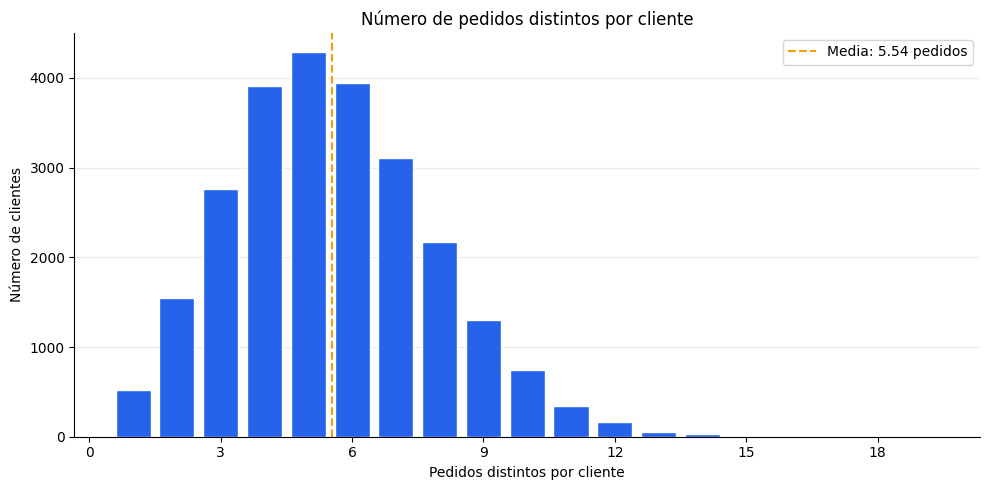

In [36]:
from matplotlib.ticker import MaxNLocator

if df_analisis.empty:
    raise ValueError("El conjunto de análisis está vacío.")

# Revisar los identificadores mediante copias temporales
ids_pedido = (
    df_analisis["order_id"]
    .astype("string").str.strip().replace("", pd.NA)
)
ids_cliente = (
    df_analisis["customer_id"]
    .astype("string").str.strip().replace("", pd.NA)
)

# Contar las repeticiones adicionales después de la primera aparición
filas_identicas_adicionales = df_analisis.duplicated().sum()
pedidos_repetidos_adicionales = (
    ids_pedido.dropna().duplicated().sum()
)

tabla_calidad_ids = pd.Series({
    "Filas idénticas adicionales en df_analisis":
        filas_identicas_adicionales,
    "Repeticiones adicionales de order_id":
        pedidos_repetidos_adicionales,
    "order_id faltantes o vacíos":
        ids_pedido.isna().sum(),
    "customer_id faltantes o vacíos":
        ids_cliente.isna().sum()
}).to_frame("Registros")

tabla_calidad_ids["Porcentaje sobre las filas"] = (
    tabla_calidad_ids["Registros"] / len(df_analisis) * 100
)

display(tabla_calidad_ids.round(3))

# Relacionar clientes y pedidos con ambos identificadores registrados
vinculos_pedidos = pd.DataFrame({
    "customer_id": ids_cliente,
    "order_id": ids_pedido
}).dropna()

pedidos_por_cliente = (
    vinculos_pedidos.groupby("customer_id")["order_id"].nunique()
)

if pedidos_por_cliente.empty:
    raise ValueError("No hay vínculos entre clientes y pedidos para graficar.")

# Número de clientes que tienen uno, dos, tres... pedidos distintos
distribucion_pedidos_cliente = (
    pedidos_por_cliente.value_counts().sort_index()
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    distribucion_pedidos_cliente.index,
    distribucion_pedidos_cliente.values,
    color="#2563EB",
    edgecolor="white"
)
ax.axvline(
    pedidos_por_cliente.mean(),
    color="#F59E0B",
    linestyle="--",
    label=f"Media: {pedidos_por_cliente.mean():.2f} pedidos"
)

ax.set_title("Número de pedidos distintos por cliente")
ax.set_xlabel("Pedidos distintos por cliente")
ax.set_ylabel("Número de clientes")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.legend()

for borde in ["top", "right"]:
    ax.spines[borde].set_visible(False)

plt.tight_layout()
plt.show()

**Análisis e interpretación.**

En **138.116 filas**, se encontraron **0 filas idénticas adicionales** y **0 repeticiones adicionales de `order_id`**. Todos los registros tienen un `order_id` presente y único, lo que es coherente con una fila por pedido.

Se identificaron **24.911 clientes con pedidos identificados**, de los cuales **24.387 tienen más de un pedido distinto**. La repetición de `customer_id` es esperable por la relación de un cliente con varios pedidos.

#### 6.3.2 Coherencia de los valores numéricos

,Registrados,Faltantes,Por revisar,Porcentaje por revisar
Variable,,,,
customer_age,138116,0,0,0.000
quantity,138116,0,0,0.000
loyalty_points_redeemed,138116,0,0,0.000
estimated_delivery_days,113559,24557,0,0.000
delivery_days,113559,24557,0,0.000
net_sales,138116,0,0,0.000


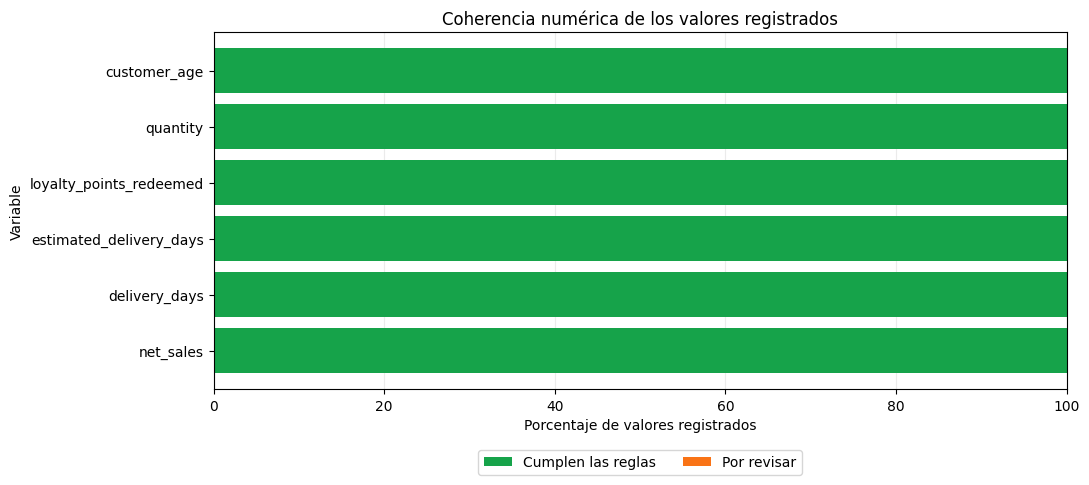

In [37]:
# Reglas: (mínimo permitido, debe ser entero)
reglas_coherencia = {
    "customer_age": (0, True),
    "quantity": (1, True),
    "loyalty_points_redeemed": (0, True),
    "estimated_delivery_days": (0, False),
    "delivery_days": (0, False),
    "net_sales": (None, False)  # Comprobar que sea numérico y finito
}

banderas_coherencia = pd.DataFrame(index=df_analisis.index)
resultados_coherencia = []

for variable, (minimo, requiere_enteros) in reglas_coherencia.items():
    originales = df_analisis[variable]
    registrados = originales.notna()

    numeros = pd.to_numeric(originales, errors="coerce")
    finitos = np.isfinite(numeros).fillna(False)
    numeros_finitos = numeros.where(finitos)

    # Valores registrados que no son numéricos o son infinitos
    alerta = registrados & ~finitos

    if minimo is not None:
        alerta |= finitos & numeros_finitos.lt(minimo)

    if requiere_enteros:
        alerta |= finitos & numeros_finitos.mod(1).ne(0)

    alerta = alerta.fillna(False)
    banderas_coherencia[variable] = alerta

    cantidad_registrada = int(registrados.sum())
    cantidad_alertas = int(alerta.sum())

    resultados_coherencia.append({
        "Variable": variable,
        "Registrados": cantidad_registrada,
        "Faltantes": int(originales.isna().sum()),
        "Por revisar": cantidad_alertas,
        "Porcentaje por revisar": (
            cantidad_alertas / cantidad_registrada * 100
            if cantidad_registrada > 0 else np.nan
        )
    })

tabla_coherencia = (
    pd.DataFrame(resultados_coherencia)
    .set_index("Variable")
)

display(tabla_coherencia.round(3))

# Mostrar ejemplos únicamente si se encuentran alertas
filas_con_alertas = banderas_coherencia.any(axis=1)

if filas_con_alertas.any():
    display(
        df_analisis.loc[
            filas_con_alertas,
            ["order_id"] + list(reglas_coherencia)
        ].head(10)
    )

# Porcentajes calculados sobre los valores registrados de cada variable
porcentaje_revision = tabla_coherencia["Porcentaje por revisar"]
porcentaje_cumplimiento = 100 - porcentaje_revision

fig, ax = plt.subplots(figsize=(11, 5))

ax.barh(
    tabla_coherencia.index,
    porcentaje_cumplimiento,
    color="#16A34A",
    label="Cumplen las reglas"
)
ax.barh(
    tabla_coherencia.index,
    porcentaje_revision,
    left=porcentaje_cumplimiento,
    color="#F97316",
    label="Por revisar"
)

ax.invert_yaxis()
ax.set_title("Coherencia numérica de los valores registrados")
ax.set_xlabel("Porcentaje de valores registrados")
ax.set_ylabel("Variable")
ax.set_xlim(0, 100)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)

plt.tight_layout()
plt.show()

**Análisis e interpretación.**

Se revisaron **seis variables cuantitativas**, con **779.582 valores registrados** en conjunto. No se identificaron filas con valores que incumplieran las reglas verificadas (**0 filas; 0,00 %**), que incluyen finitud numérica, mínimos permitidos y carácter entero cuando corresponde.

Este resultado **no equivale a certificar la calidad completa del dataset**: la revisión no sustituye la comprobación semántica de fechas, monedas o relaciones entre tablas. Además, los faltantes de las variables de entrega se evaluaron por separado, porque responden a un patrón asociado con el estado del pedido.

#### 6.3.3 Detección de valores atípicos mediante IQR

,Población,N válido,Q1,Q3,IQR,Límite inferior,Límite superior,Posibles atípicos,Porcentaje atípico
Variable,,,,,,,,,
customer_age,Clientes únicos,24911,32.000,60.000,28.000,-10.000,102.000,0,0.000
quantity,Todos los pedidos,138116,3.000,8.000,5.000,-4.500,15.500,1197,0.867
net_sales,Pedidos en USD,82600,432.370,"1,684.542","1,252.173","-1,445.889","3,562.801",3882,4.700
loyalty_points_redeemed,Todos los pedidos,138116,3.000,71.000,68.000,-99.000,173.000,9172,6.641
estimated_delivery_days,Pedidos Completed,113559,2.000,6.000,4.000,-4.000,12.000,0,0.000
delivery_days,Pedidos Completed,113559,2.000,7.000,5.000,-5.500,14.500,0,0.000


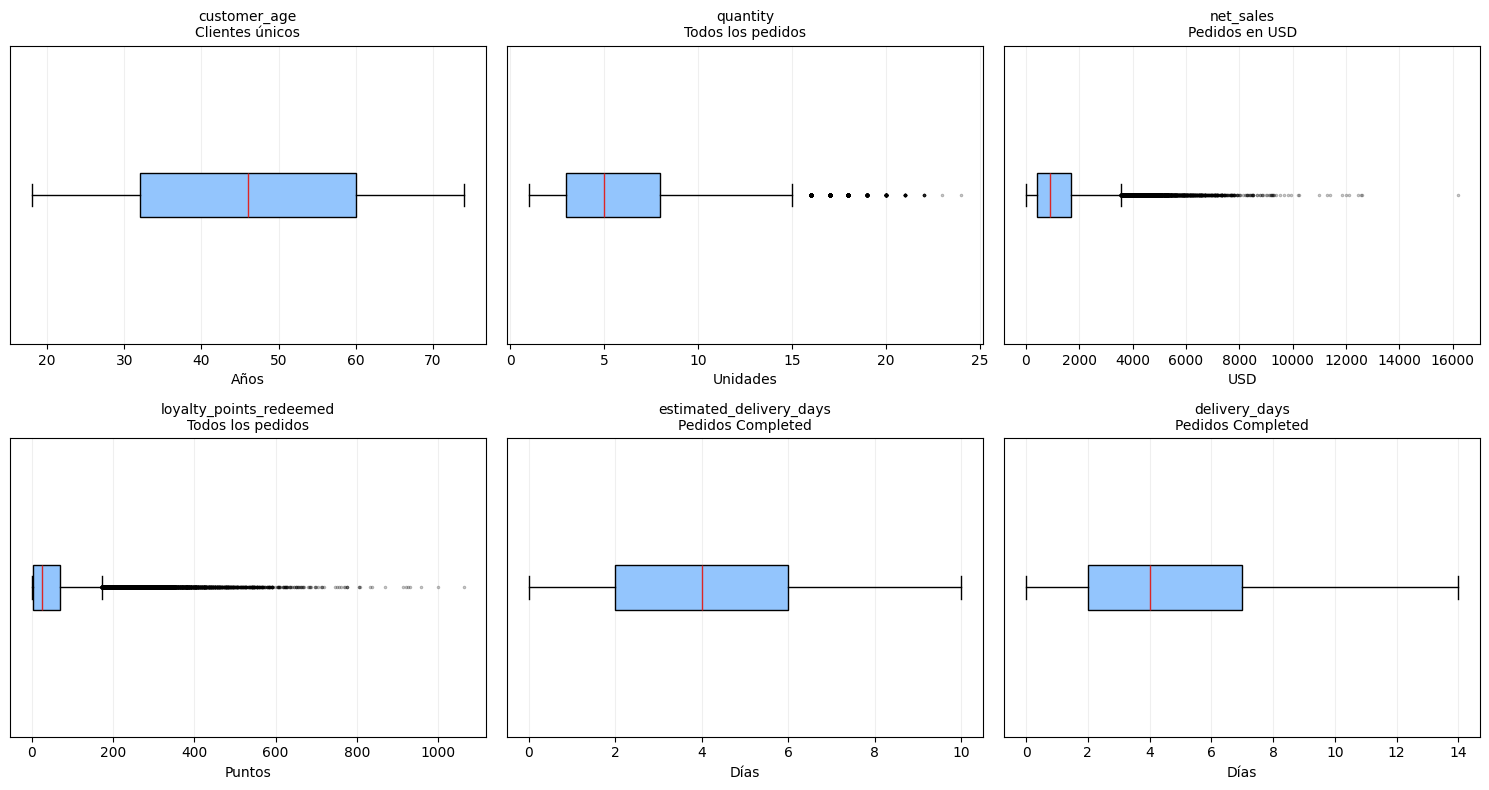

In [38]:
# Conservar las poblaciones utilizadas en el análisis univariado
bases_iqr = {
    "customer_age": (
        edades_clientes, "Clientes únicos", "Años"
    ),
    "quantity": (
        unidades_pedido, "Todos los pedidos", "Unidades"
    ),
    "net_sales": (
        ventas_usd, "Pedidos en USD", "USD"
    ),
    "loyalty_points_redeemed": (
        puntos_canjeados, "Todos los pedidos", "Puntos"
    ),
    "estimated_delivery_days": (
        dias_estimados, "Pedidos Completed", "Días"
    ),
    "delivery_days": (
        dias_reales, "Pedidos Completed", "Días"
    )
}

resultados_iqr = []
valores_atipicos_iqr = {}
variables_iqr_cero = []

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, (variable, datos) in zip(axes.flat, bases_iqr.items()):
    serie_original, poblacion, unidad = datos

    # Evaluar únicamente valores numéricos finitos
    serie = (
        pd.to_numeric(serie_original, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    if serie.empty:
        ax.set_title(variable)
        ax.text(
            0.5, 0.5, "Sin valores disponibles",
            ha="center", va="center",
            transform=ax.transAxes
        )
        ax.set_axis_off()
        continue

    # Calcular los límites de la regla IQR
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    es_atipico = (
        (serie < limite_inferior) |
        (serie > limite_superior)
    )

    # Guardar los valores señalados para su revisión posterior
    valores_atipicos_iqr[variable] = serie.loc[es_atipico]

    if iqr == 0:
        variables_iqr_cero.append(variable)

    resultados_iqr.append({
        "Variable": variable,
        "Población": poblacion,
        "N válido": len(serie),
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Límite inferior": limite_inferior,
        "Límite superior": limite_superior,
        "Posibles atípicos": int(es_atipico.sum()),
        "Porcentaje atípico": es_atipico.mean() * 100
    })

    # Dibujar los datos completos de cada población
    ax.boxplot(
        serie,
        vert=False,
        whis=1.5,
        patch_artist=True,
        boxprops={"facecolor": "#93C5FD"},
        medianprops={"color": "#DC2626"},
        flierprops={
            "marker": ".",
            "markersize": 3,
            "alpha": 0.3
        }
    )

    ax.set_title(f"{variable}\n{poblacion}", fontsize=10)
    ax.set_xlabel(unidad)
    ax.set_yticks([])
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.20)

if not resultados_iqr:
    raise ValueError("No hay valores disponibles para aplicar la regla IQR.")

tabla_iqr = (
    pd.DataFrame(resultados_iqr)
    .set_index("Variable")
)

display(tabla_iqr.round(3))

if variables_iqr_cero:
    print("Variables con IQR igual a cero:", ", ".join(variables_iqr_cero))
    print(
        "Sus límites coinciden. Las alertas deben interpretarse "
        "junto con la concentración de los valores."
    )

plt.tight_layout()
plt.show()

# Para inspeccionar valores señalados, por ejemplo:
# display(valores_atipicos_iqr["net_sales"].sort_values(ascending=False).head(10))

**Análisis e interpretación.**

La regla de **1,5 × IQR** se aplicó a **seis variables cuantitativas**, respetando las distintas poblaciones señaladas en la tabla. Se identificaron posibles valores atípicos en **tres** de ellas: **`loyalty_points_redeemed` (9.172; 6,64 %)**, **`net_sales` (3.882; 4,70 %)** y **`quantity` (1.197; 0,87 %)**.

En edad, días estimados y días reales no se detectaron observaciones fuera de los límites calculados. En los puntos canjeados se observa la mayor proporción de posibles atípicos, por lo que conviene examinar el contexto de esos pedidos antes de recortar o eliminar valores. La regla IQR identifica valores extremos desde un criterio descriptivo, **no errores confirmados**; su tratamiento quedará justificado en la fase de preprocesamiento.

---

### 6.4 Síntesis del diagnóstico exploratorio

Los resultados respaldan la continuidad del proyecto con varias precauciones metodológicas. Los análisis de importes deben mantener una **moneda homogénea (USD)**; la clasificación entre `Completed` y `Returned` debe considerar el **desbalance de estados** y excluir información generada después de conocer el resultado del pedido. Los faltantes de `delivery_days`, `estimated_delivery_days` y `review_sentiment` **no parecen aleatorios respecto al estado** en los datos revisados y no se deben imputar sin justificarlo.

En la exploración multivariada, la asociación de `net_sales` con cantidad y puntos canjeados contrasta con la escasa asociación monotónica del importe con edad o tiempos de entrega. Las pruebas χ² univariadas no aportan evidencia de asociación entre el estado del pedido y las siete categorías examinadas; esto **no descarta posibles patrones conjuntos o no lineales**. Por último, los valores extremos detectados por IQR permanecen identificados, pero no se eliminan en esta fase: su tratamiento requiere análisis y justificación durante el preprocesamiento.

In [39]:

from google.colab import files

df_analisis.to_csv("base_depurada_fase1.csv", index=False)
files.download("base_depurada_fase1.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>